# Nhóm 3: Thay đổi độ phân tán (phương sai) của covariates
*Mục tiêu:* Độ phân tán ($\sigma^2$ hoặc ma trận hiệp phương sai $\Sigma$) đại diện cho mức độ rải rác và dải biến thiên của dữ liệu. Nếu covariates có độ phân tán quá lớn, đường cong phân phối sẽ bị bẹt ra, sinh ra nhiều giá trị ngoại lai (outliers). Những giá trị cực đoan này khi đưa vào mô hình Propensity Score (Logistic Regression) sẽ đẩy xác suất can thiệp về sát biên $0$ hoặc $1$, làm suy yếu nghiêm trọng vùng chồng lấp (overlap). Mục tiêu là **khảo sát xem sự phình to của phương sai ảnh hưởng thế nào đến hiện tượng bùng nổ phương sai (variance explosion) của các bộ ước lượng, cũng như đánh giá giới hạn chịu đựng của chúng trước khi Khoảng tin cậy (CI) mất đi ý nghĩa.**

*Cơ chế sinh dữ liệu:* Giữ cố định kỳ vọng ($\mu = 0$) cho tất cả các biến, nhưng can thiệp vào phương sai ($\sigma^2$) của hiệp biến $X_2$. Dựa trên bảng thông số cấu hình cơ sở, ta thiết lập 5 kịch bản phân tán tuyến tính:
- Kịch bản 1 (Baseline - Phân tán chuẩn): $X_1 \sim \mathcal{N}(0;1),\ X_2 \sim \mathcal{N}(0;1)$. Dữ liệu mốc đối chứng, không có ngoại lai bất thường.
- Kịch bản 2 (Phân tán thấp): $X_1 \sim \mathcal{N}(0;1),\ X_2 \sim \mathcal{N}(0;0.5)$. Dữ liệu co cụm chặt chẽ quanh trung bình, hạn chế tối đa các giá trị cực đoan.
- Kịch bản 3 (Phân tán cao vừa): $X_1 \sim \mathcal{N}(0;1),\ X_2 \sim \mathcal{N}(0;2)$. Dữ liệu bắt đầu dàn trải, đuôi phân phối dài hơn bình thường.
- Kịch bản 4 (Phân tán lớn): $X_1 \sim \mathcal{N}(0;1),\ X_2 \sim \mathcal{N}(0;5)$. Phổ dữ liệu rất rộng, xuất hiện thường xuyên các giá trị ngoại lai đẩy $e(X)$ ra xa trung tâm.
- Kịch bản 5 (Phân tán rất lớn - Stress-test): $X_1 \sim \mathcal{N}(0;1),\ X_2 \sim \mathcal{N}(0;10)$. Phân tán cực đại, giả định Positivity bị đe dọa nghiêm trọng do đặc tính của chính phân phối dữ liệu chứ không phải do chênh lệch kỳ vọng.

*Đại lượng cần ước lượng:* ATE (với hiệu ứng $\tau_0$ đồng nhất).

*Phương pháp:* Bao gồm 4 phương pháp ước lượng (Cập nhật 4/11).

*Tiêu chí hiệu suất:* Bias, RMSE, SE, độ phủ CI 95%, độ rộng CI và SMD. (Trọng tâm quan sát sự gia tăng đột biến của SE - Standard Error, trọng số lớn nhất (Max Weight), sự phình to của độ rộng CI, và sự sụt giảm của Kích thước mẫu hiệu dụng (ESS) tỷ lệ thuận với mức tăng của phương sai).

| Bước | Nội dung |
|---|---|
| 0 | Thiết lập, DGP và 5 kịch bản |
| 1 | Nhìn dữ liệu: phân phối $X_2$ và $e(X)$ theo nhóm |
| 2 | Quét liên tục phương sai $\sigma_2^2$: chẩn đoán overlap và hiệu năng |
| 3 | Phân tích từng kịch bản (một lần chạy): balance, Love plot, ESS, ước lượng + CI |
| 4 | Mô phỏng lặp 1000 lần, $n\in\{500,2000\}$: bias, SD, SE, RMSE, độ phủ CI, độ rộng CI, SMD, ESS, max weight |
| 5 | Độ nhạy theo độ mạnh confounding $\gamma$ |
| 6 | Xử lý: trimming, clipping, overlap weighting |
| 7 | Kết luận và quy trình |

In [3]:
import os, sys, time, warnings
sys.path.insert(0, os.getcwd())
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
# Add distribution_scenario directory (1 level up) to sys.path
module_parent_dir = os.path.abspath("..")
if module_parent_dir not in sys.path:
    sys.path.append(module_parent_dir)
from module.distribution import Simulation
from module.dispersion import DispersionSimulation, DISPERSION_SCENARIOS, dispersion_name   # nhóm 3 (file mới)
from module.balance import check_balance, summarize, effective_sample_size, trim_summary, overlap_mask
from module.methods import estimate_all, estimate_ps
from module.evaluation import estimate_with_se, monte_carlo, diagnostics, METHODS_ALL         # dùng chung với nhóm 2

SEED, N, GAMMA, REPS, NS = 251, 2000, (0.5, 0.5), 1000, (500, 2000)
NAMES = ["disp_v05", "disp_v1", "disp_v2", "disp_v5", "disp_v10"]       # xếp theo phương sai tăng dần
SHORT = {"disp_v05": "2. var=0.5", "disp_v1": "1. var=1 (baseline)", "disp_v2": "3. var=2", "disp_v5": "4. var=5", "disp_v10": "5. var=10"}
CORE = ["naive", "ols", "iptw", "aipw"]                                  # 4 phương pháp chính

BLUE, RED, ORANGE, GREEN, INK, GRAY, PURPLE = "#3fa6e1", "#e04444", "#d26f28", "#7ED386", "#0b0b0b", "#9a9a94", "#8a63c7"
MCOL = {"naive": GRAY, "ols": BLUE, "iptw": RED, "iptw_ht": ORANGE, "aipw": GREEN,
        "iptw_trim": "#b83a3a", "aipw_trim": "#3f9a49", "ow": PURPLE, "match": "#555555"}
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e", "text.color": INK,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "axes.titlesize": 10, "axes.titleweight": "regular", "font.size": 9, "figure.dpi": 110})
pd.set_option("display.width", 220); pd.set_option("display.max_columns", None)
DispersionSimulation.list_scenarios()

,id,name,description,var2
0,1,disp_v1,"X1~N(0;1), X2~N(0;1)",1.0
1,2,disp_v05,"X1~N(0;1), X2~N(0;0.5)",0.5
2,3,disp_v2,"X1~N(0;1), X2~N(0;2)",2.0
3,4,disp_v5,"X1~N(0;1), X2~N(0;5)",5.0
4,5,disp_v10,"X1~N(0;1), X2~N(0;10)",10.0


## 0. Mô hình sinh dữ liệu
|Mô tả|
|---------|
|$X_1\sim N(0;1)$|
|$X_2\sim N(0;v)$ với $v\in\{0.5,1,2,5,10\}$ là **phương sai**. Vì $X_2$ đối xứng quanh 0 nên $\gamma_0$ hiệu chỉnh cho 50% treated luôn $\approx$ 0|
|$e(X)=\sigma(\gamma_0+\gamma_1X_1+\gamma_2X_2)$|
|$A\sim\text{Bernoulli}(e)$|
|$m(X)=0.5X_1+0.5X_2$|
|$\tau_0=2$| $\varepsilon\sim N(0,1)$. Mặc định $\gamma=(0.5,0.5)$. 


Ước lượng: 4 phương pháp chính `naive`, `ols`, `iptw` (Hajek), `aipw`; phần xử lý dùng thêm `iptw_trim`, `aipw_trim`, `ow` (ATO). SE theo hàm ảnh hưởng.

In [4]:
rows = []
for k in NAMES:
    s = DispersionSimulation(k, n=N, seed=SEED)
    rows.append({"kịch bản": SHORT[k], "var(X2)": s.var2, "gamma0": s.gamma0,
                 "var(gamma'X)": s.gamma1**2 + s.gamma2**2 * s.var2, **diagnostics(s.generate())})
display(pd.DataFrame(rows).round(3))

,kịch bản,var(X2),gamma0,var(gamma'X),treated_rate,e_outside,max_weight,ess_ratio,trim_drop
0,2. var=0.5,0.5,-0.001,0.375,0.492,0.000,7.653,0.888,0.000
1,1. var=1 (baseline),1.0,-0.001,0.500,0.488,0.000,10.226,0.856,0.000
2,3. var=2,2.0,-0.001,0.750,0.486,0.000,9.899,0.800,0.000
3,4. var=5,5.0,-0.002,1.500,0.482,0.000,20.464,0.619,0.023
4,5. var=10,10.0,-0.002,2.750,0.479,0.006,52.612,0.394,0.103


## 1. Nhìn dữ liệu

Hàng trên: $X_2$ theo nhóm (cùng trục để thấy độ rộng). Hàng dưới: $e(X)$ thật theo nhóm.

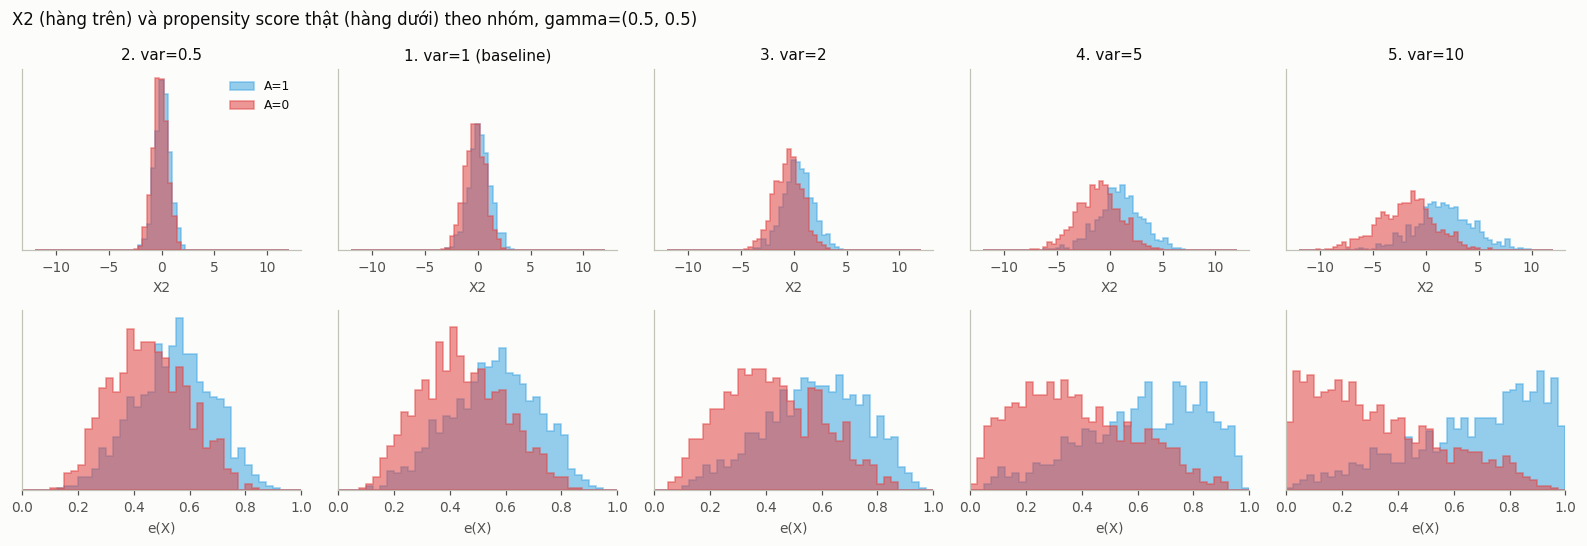

In [5]:
def overview_grid(gamma=GAMMA, n=N, seed=SEED, names=NAMES):
    fig, axes = plt.subplots(2, len(names), figsize=(2.9 * len(names), 5.0), sharey="row")
    for j, k in enumerate(names):
        df = DispersionSimulation(k, n=n, seed=seed, gamma=gamma).generate()
        for a, col, lab in [(1, BLUE, "A=1"), (0, RED, "A=0")]:
            axes[0, j].hist(df.loc[df.A == a, "X2"], bins=np.linspace(-12, 12, 60), color=col, alpha=0.55,
                            histtype="stepfilled", edgecolor=col, label=lab)
            axes[1, j].hist(df.loc[df.A == a, "e"], bins=np.linspace(0, 1, 41), color=col, alpha=0.55,
                            histtype="stepfilled", edgecolor=col)
        axes[0, j].set_title(SHORT[k]); axes[0, j].set_xlabel("X2"); axes[1, j].set_xlabel("e(X)"); axes[1, j].set_xlim(0, 1)
        axes[0, j].set_yticks([]); axes[1, j].set_yticks([])
    axes[0, 0].legend(frameon=False, fontsize=8)
    fig.suptitle(f"X2 (hàng trên) và propensity score thật (hàng dưới) theo nhóm, gamma={gamma}", x=0.01, ha="left")
    fig.tight_layout(); plt.show()
overview_grid()

**Nhận xét.** Phương sai tăng thì $X_2$ trải rộng và $e(X)$ chuyển từ hình chuông quanh 0.5 sang gần phẳng ($v=5$) rồi dồn về hai biên ($v=10$: control chồng ở gần 0, treated chồng ở gần 1). Khác nhóm 2, hai nhóm vẫn cân xứng (treated $\approx$ 50% ở mọi kịch bản) và vẫn chồng lấp ở vùng giữa; cái mất đi là **các quan sát ở hai đuôi**, nơi $e(X)$ sát 0 hoặc 1.

## 2. Quét liên tục phương sai

Quét $v\in\{0.25,\dots,20\}$ (mỗi điểm lặp 300 lần, $n=2000$, trục $v$ dùng thang log) với $\gamma=0.5$ và $\gamma=1$, để xác định *điểm gãy* thay vì chỉ 5 điểm rời rạc.

In [6]:
VARS = [0.25, 0.5, 1, 2, 3, 5, 7, 10, 15, 20]
SWEEP_M = ["ols", "iptw", "aipw", "ow"]
def sweep(gamma, reps=300, n=N):
    out = []
    for v in VARS:
        sim = DispersionSimulation(dispersion_name(v), n=n, seed=SEED, gamma=gamma)
        summ, dg = monte_carlo(sim, reps=reps, methods=SWEEP_M)
        out.append({"var": v, **dg.to_dict(), **{f"{m}_{c}": summ.loc[m, c] for m in SWEEP_M
                    for c in ("bias", "sd", "rmse", "coverage", "ci_width", "mean_se")}})
    return pd.DataFrame(out).set_index("var")
t0 = time.time(); SW = {g: sweep((g, g)) for g in (0.5, 1.0)}; print(f"xong sau {time.time()-t0:.0f}s")
for g in SW: print(f"gamma={g}"); display(SW[g][["e_outside", "max_weight", "ess_ratio", "trim_drop"]].round(3).T)

xong sau 30s
gamma=0.5


var,0.25,0.50,1.00,2.00,3.00,5.00,7.00,10.00,15.00,20.00
e_outside,0.000,0.000,0.000,0.000,0.000,0.000,0.001,0.006,0.021,0.045
max_weight,6.756,7.689,9.475,13.363,17.250,26.602,38.669,54.133,93.027,144.177
ess_ratio,0.920,0.905,0.874,0.812,0.755,0.646,0.550,0.445,0.323,0.246
trim_drop,0.000,0.000,0.000,0.001,0.004,0.017,0.038,0.077,0.142,0.201


gamma=1.0


var,0.25,0.50,1.00,2.00,3.00,5.00,7.00,10.00,15.00,20.00
e_outside,0.000,0.000,0.001,0.008,0.022,0.061,0.105,0.166,0.252,0.317
max_weight,21.964,26.533,36.515,59.022,91.817,175.689,202.018,292.505,307.796,432.439
ess_ratio,0.697,0.645,0.553,0.418,0.325,0.220,0.174,0.131,0.102,0.089
trim_drop,0.010,0.017,0.038,0.091,0.142,0.231,0.300,0.377,0.464,0.522


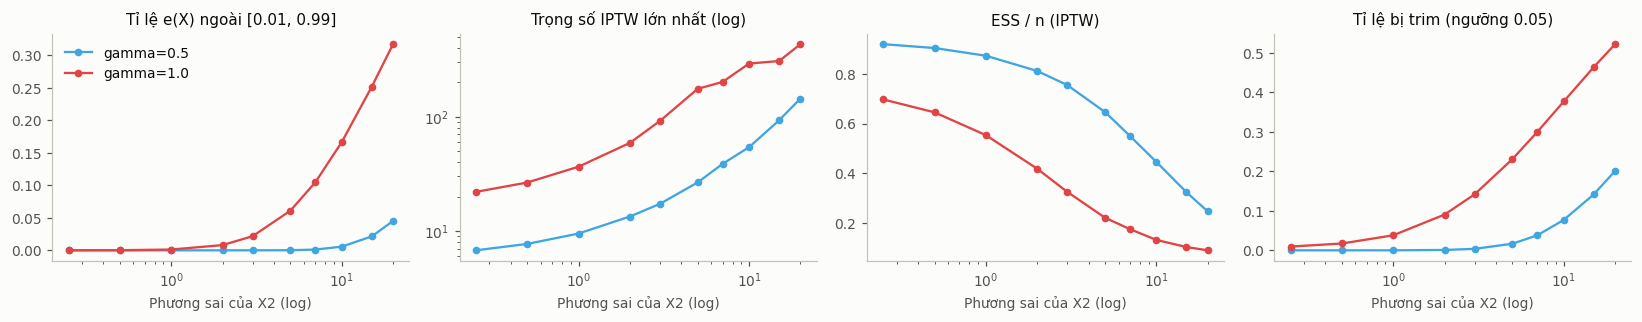

In [7]:
def plot_sweep_diag(SW):
    items = [("e_outside", "Tỉ lệ e(X) ngoài [0.01, 0.99]"), ("max_weight", "Trọng số IPTW lớn nhất (log)"),
             ("ess_ratio", "ESS / n (IPTW)"), ("trim_drop", "Tỉ lệ bị trim (ngưỡng 0.05)")]
    fig, axes = plt.subplots(1, 4, figsize=(15, 3.0))
    for ax, (c, t) in zip(axes, items):
        for g, col in ((0.5, BLUE), (1.0, RED)):
            ax.plot(SW[g].index, SW[g][c], "-o", ms=4, color=col, label=f"gamma={g}")
        ax.set_xscale("log"); ax.set_title(t); ax.set_xlabel("Phương sai của X2 (log)")
        if c == "max_weight": ax.set_yscale("log")
    axes[0].legend(frameon=False); fig.tight_layout(); plt.show()

plot_sweep_diag(SW)

**Nhận xét (mỗi điểm 300 lần lặp, $n=2000$).**

**Overlap xấu đi đều theo phương sai.** 
- $\gamma=0.5$: 
    - ESS/n giảm dần từ 0.87 ($v=1$) -> 0.65 ($v=5$) -> 0.45 ($v=10$) -> 0.25 ($v=20$)
    - Trọng số lớn nhất 9.5 -> 27 -> 54 -> 144
    - Tỉ lệ bị trim 0 -> 1.7% -> 7.7% -> 20%
    - $e(X)$ ngoài [0.01, 0.99] vẫn 0 đến $v\approx5$ và chỉ 0.6% ở $v=10$.
- $\gamma=1$: 
    - ESS/n 0.55 -> 0.22 -> 0.13 -> 0.09
    - max weight 37 -> 176 -> 293 -> 432
    - $e(X)$ ngoài biên 0.1% -> 6.1% -> 16.6% -> 32%.

## 3. Phân tích từng kịch bản (một lần chạy)

`inspect_case(name)`: chẩn đoán overlap, phân phối $X_2$ và $e(X)$, bảng balance trước/sau IPTW, Love plot, ESS, forest plot ATE ước lượng kèm CI 95%.

In [8]:
def love_plot(table, ax=None, title="Covariate balance trước và sau gán trọng số", threshold=0.1):
    t = table.reindex(table["smd_before"].abs().sort_values(ascending=False).index)
    k, ypos = len(t), np.arange(len(t))
    own = ax is None
    if own: fig, ax = plt.subplots(figsize=(5.2, max(2.0, 0.5 * k + 1.2)))
    for s in (-threshold, threshold): ax.axvline(s, color=RED, lw=1, ls="--")
    ax.axvline(0, color=RED, lw=0.8, alpha=0.6)
    ax.scatter(t["smd_before"], ypos, color=GREEN, s=45, zorder=3, label="Trước weighting")
    ax.scatter(t["smd_after"], ypos, color=BLUE, s=45, zorder=3, label="Sau IPTW")
    ax.set_yticks(ypos); ax.set_yticklabels(t.index); ax.set_ylim(k - 0.5, -0.5)
    ax.set_xlabel("Standardized mean difference"); ax.set_title(title); ax.legend(frameon=False, fontsize=8)
    if own: plt.tight_layout(); plt.show()

def forest(ax, res, truth, title="ATE ước lượng và CI 95%"):
    r = res.reindex(METHODS_ALL)
    for i, (m, row) in enumerate(r.iterrows()):
        if np.isfinite(row["se"]): ax.plot([row["lo"], row["hi"]], [i, i], color=MCOL[m], lw=2)
        ax.scatter(row["est"], i, color=MCOL[m], s=40, zorder=3)
    ax.axvline(truth, color=INK, lw=1, ls="--")
    ax.set_yticks(range(len(r))); ax.set_yticklabels(r.index); ax.set_ylim(len(r) - 0.5, -0.5)
    ax.set_xlabel("ATE"); ax.set_title(title)

def inspect_case(name, n=N, seed=SEED, gamma=GAMMA, trim=None, trim_mode="drop"):
    sim = DispersionSimulation(name, n=n, seed=seed, gamma=gamma)
    df = sim.generate()
    print(f"Kịch bản: {SHORT[name]} | {sim.description} | n={n}, gamma={gamma}, gamma0={sim.gamma0:.3f}, ATE thật={sim.ate}")
    display(Simulation.summary(df).round(3).to_frame("giá trị").T)
    fig, axes = plt.subplots(1, 3, figsize=(12, 2.9))
    for a, col, lab in [(1, BLUE, "A=1"), (0, RED, "A=0")]:
        axes[0].hist(df.loc[df.A == a, "X2"], bins=40, color=col, alpha=0.55, histtype="stepfilled", edgecolor=col, label=lab)
        axes[1].hist(df.loc[df.A == a, "e"], bins=np.linspace(0, 1, 41), color=col, alpha=0.55, histtype="stepfilled", edgecolor=col, label=lab)
    axes[0].set_title("Phân phối X2 theo nhóm"); axes[1].set_title("Propensity score e(X) theo nhóm")
    axes[0].set_yticks([]); axes[1].set_yticks([]); axes[1].legend(frameon=False)
    res = estimate_with_se(df, trim=0.05); forest(axes[2], res, sim.ate)
    fig.tight_layout(); plt.show()
    if trim is not None:
        display(trim_summary(df, trim, trim_mode=trim_mode).to_frame("giá trị").T)
    print("Balance trước / sau gán trọng số IPTW")
    tbl = check_balance(df, trim=trim, trim_mode=trim_mode); display(tbl.round(3)); love_plot(tbl, title=SHORT[name])
    print("Cỡ mẫu hiệu dụng (ESS) của trọng số IPTW"); display(effective_sample_size(df, trim=trim, trim_mode=trim_mode).round(3))
    out = res[["est", "se", "lo", "hi"]].copy(); out["bias"] = out["est"] - sim.ate
    print(f"ATE ước lượng (thật = {sim.ate}); iptw_trim/aipw_trim dùng trim=0.05, ow ước lượng ATO"); display(out.round(3).T)
    return df

### 1. Baseline: $X_2\sim N(0;1)$

Mốc đối chứng, không có ngoại lai bất thường.

Kịch bản: 1. var=1 (baseline) | X1~N(0;1), X2~N(0;1) | n=2000, gamma=(0.5, 0.5), gamma0=-0.001, ATE thật=2.0


,n,treated_rate,e_min,e_max,e_outside,max_weight,ess_ratio
giá trị,2000.0,0.488,0.088,0.938,0.0,9.651,0.867


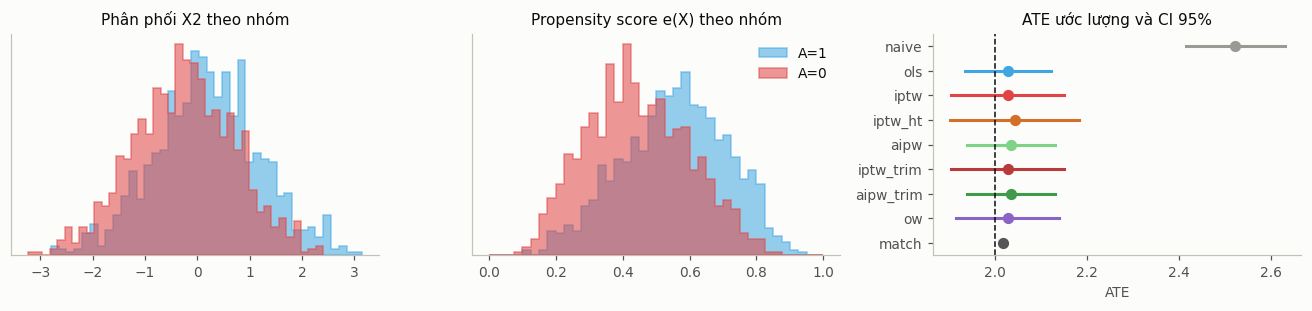

Balance trước / sau gán trọng số IPTW


,smd_before,vr_before,balanced_before,smd_after,vr_after,balanced_after
X1,0.534,1.155,False,0.051,1.149,True
X2,0.452,1.084,False,-0.037,1.129,True


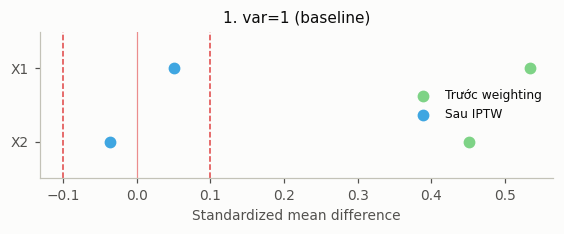

Cỡ mẫu hiệu dụng (ESS) của trọng số IPTW


,n,n_kept,ess,ess_ratio
toàn mẫu,2000,2000,1734.264,0.867
treated (A=1),977,977,834.721,0.854
control (A=0),1023,1023,900.303,0.880


ATE ước lượng (thật = 2.0); iptw_trim/aipw_trim dùng trim=0.05, ow ước lượng ATO


,naive,ols,iptw,iptw_ht,aipw,iptw_trim,aipw_trim,ow,match
est,2.522,2.027,2.027,2.042,2.034,2.027,2.034,2.027,2.017
se,0.055,0.048,0.063,0.072,0.049,0.063,0.049,0.057,NaN
lo,2.415,1.934,1.904,1.902,1.939,1.904,1.939,1.915,NaN
hi,2.630,2.120,2.150,2.182,2.130,2.150,2.130,2.139,NaN
bias,0.522,0.027,0.027,0.042,0.034,0.027,0.034,0.027,0.017


In [9]:
df1 = inspect_case("disp_v1")

**Nhận xét.** Baseline: SMD của X1, X2 trước weighting 0.53 và 0.45, sau IPTW còn 0.05 và −0.04; ESS/n 0.87, max weight 9.7. Naive chệch +0.52, các phương pháp còn lại cách 2 chưa tới 0.04.

### 2. Phân tán thấp: $X_2\sim N(0;0.5)$

Dữ liệu co cụm; kỳ vọng $e(X)$ rất ôn hòa, trọng số ổn định.

Kịch bản: 2. var=0.5 | X1~N(0;1), X2~N(0;0.5) | n=2000, gamma=(0.5, 0.5), gamma0=-0.001, ATE thật=2.0


,n,treated_rate,e_min,e_max,e_outside,max_weight,ess_ratio
giá trị,2000.0,0.492,0.113,0.916,0.0,6.901,0.904


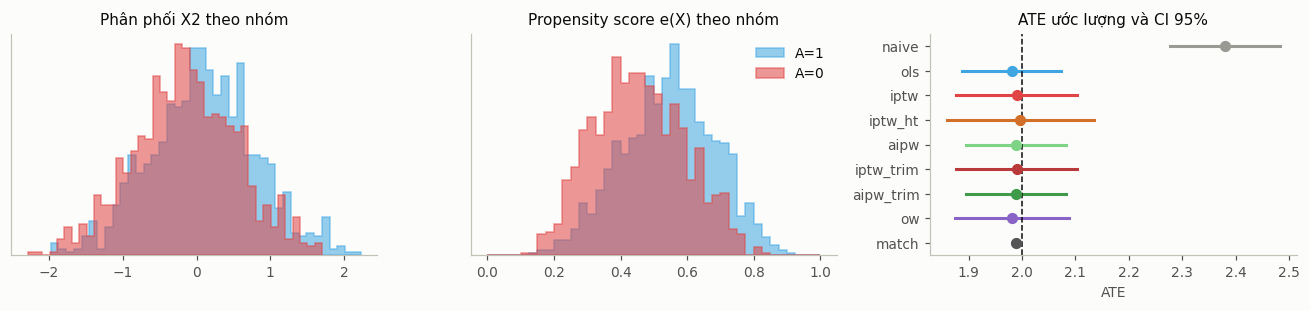

Balance trước / sau gán trọng số IPTW


,smd_before,vr_before,balanced_before,smd_after,vr_after,balanced_after
X1,0.535,1.185,False,0.054,1.175,True
X2,0.347,1.056,False,-0.002,1.075,True


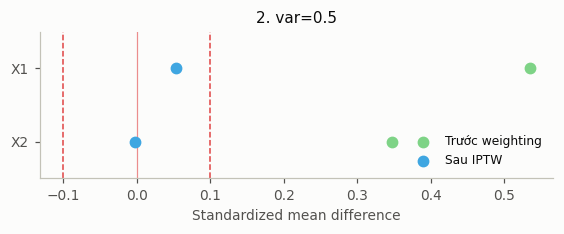

Cỡ mẫu hiệu dụng (ESS) của trọng số IPTW


,n,n_kept,ess,ess_ratio
toàn mẫu,2000,2000,1807.823,0.904
treated (A=1),983,983,883.286,0.899
control (A=0),1017,1017,924.643,0.909


ATE ước lượng (thật = 2.0); iptw_trim/aipw_trim dùng trim=0.05, ow ước lượng ATO


,naive,ols,iptw,iptw_ht,aipw,iptw_trim,aipw_trim,ow,match
est,2.380,1.981,1.990,1.997,1.989,1.990,1.989,1.981,1.988
se,0.053,0.047,0.058,0.070,0.048,0.058,0.048,0.054,NaN
lo,2.276,1.888,1.876,1.859,1.895,1.876,1.895,1.875,NaN
hi,2.483,2.073,2.103,2.134,2.083,2.103,2.083,2.088,NaN
bias,0.380,-0.019,-0.010,-0.003,-0.011,-0.010,-0.011,-0.019,-0.012


In [10]:
df2 = inspect_case("disp_v05")

**Nhận xét.** Phân tán thấp: $e(X)\in[0.11, 0.92]$, ESS/n 0.90, max weight 6.9. SMD của X2 trước weighting thấp hơn baseline (0.35), naive chệch +0.38 (nhỏ hơn baseline vì $X_2$ ít giải thích $A$ và $Y$ hơn). Mọi phương pháp ngoài naive cách 2 không quá 0.02, SE của IPTW 0.058.

### 3. Phân tán vừa: $X_2\sim N(0;2)$

Đuôi dài hơn; kỳ vọng trọng số lớn nhất tăng nhẹ.

Kịch bản: 3. var=2 | X1~N(0;1), X2~N(0;2) | n=2000, gamma=(0.5, 0.5), gamma0=-0.001, ATE thật=2.0


,n,treated_rate,e_min,e_max,e_outside,max_weight,ess_ratio
giá trị,2000.0,0.486,0.062,0.96,0.0,8.742,0.822


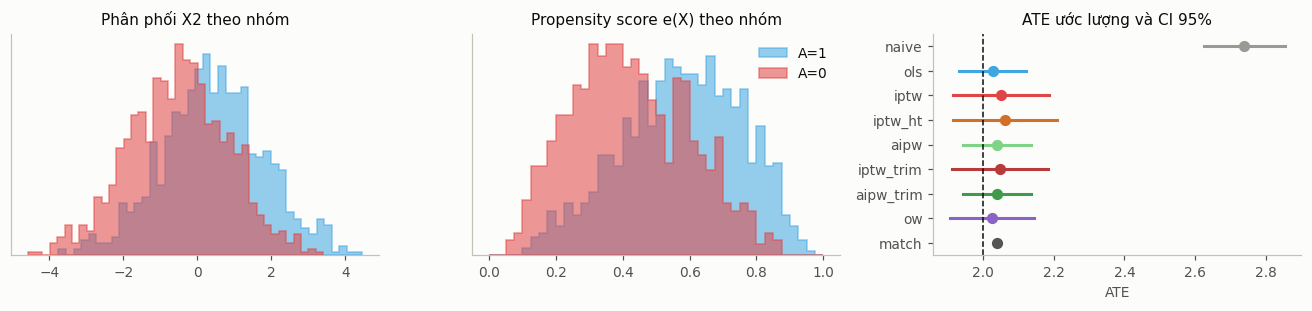

Balance trước / sau gán trọng số IPTW


,smd_before,vr_before,balanced_before,smd_after,vr_after,balanced_after
X1,0.474,1.137,False,0.022,1.148,True
X2,0.691,1.064,False,0.048,1.100,True


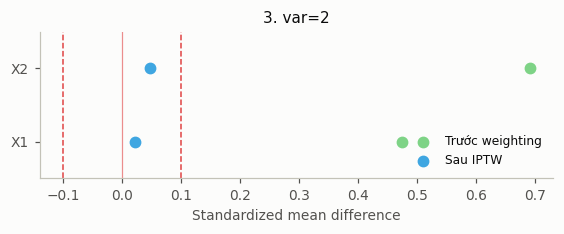

Cỡ mẫu hiệu dụng (ESS) của trọng số IPTW


,n,n_kept,ess,ess_ratio
toàn mẫu,2000,2000,1643.052,0.822
treated (A=1),973,973,784.609,0.806
control (A=0),1027,1027,859.646,0.837


ATE ước lượng (thật = 2.0); iptw_trim/aipw_trim dùng trim=0.05, ow ước lượng ATO


,naive,ols,iptw,iptw_ht,aipw,iptw_trim,aipw_trim,ow,match
est,2.739,2.027,2.050,2.062,2.039,2.048,2.039,2.025,2.038
se,0.058,0.048,0.069,0.075,0.050,0.069,0.050,0.061,NaN
lo,2.625,1.932,1.914,1.915,1.942,1.913,1.942,1.906,NaN
hi,2.853,2.122,2.185,2.209,2.136,2.183,2.136,2.144,NaN
bias,0.739,0.027,0.050,0.062,0.039,0.048,0.039,0.025,0.038


In [11]:
df3 = inspect_case("disp_v2")

**Nhận xét.** $v=2$: SMD của X2 trước weighting tăng lên 0.69 (so với 0.45), sau IPTW còn 0.048; ESS/n 0.82; naive chệch +0.74. IPTW, AIPW lệch +0.05 và +0.04 so với 2, nằm trong CI (SE 0.069 và 0.050); mức tăng SE so với baseline còn nhỏ.

### 4. Phân tán lớn: $X_2\sim N(0;5)$

Nhiều giá trị ngoại lai đẩy $e(X)$ ra xa trung tâm.

Kịch bản: 4. var=5 | X1~N(0;1), X2~N(0;5) | n=2000, gamma=(0.5, 0.5), gamma0=-0.002, ATE thật=2.0


,n,treated_rate,e_min,e_max,e_outside,max_weight,ess_ratio
giá trị,2000.0,0.482,0.022,0.984,0.0,17.367,0.661


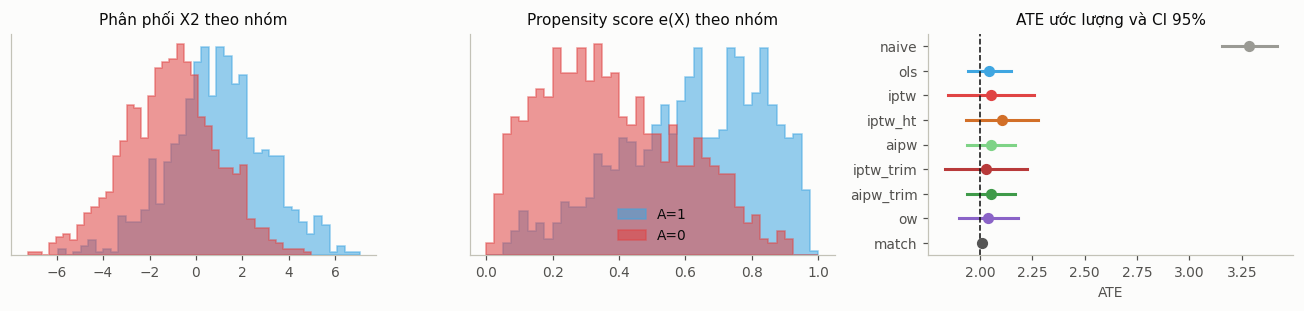

Balance trước / sau gán trọng số IPTW


,smd_before,vr_before,balanced_before,smd_after,vr_after,balanced_after
X1,0.442,1.045,False,0.045,1.042,True
X2,1.004,1.064,False,0.036,1.235,True


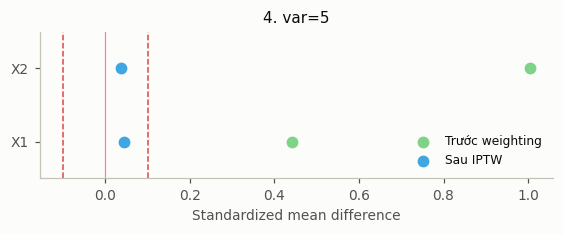

Cỡ mẫu hiệu dụng (ESS) của trọng số IPTW


,n,n_kept,ess,ess_ratio
toàn mẫu,2000,2000,1322.051,0.661
treated (A=1),964,964,586.902,0.609
control (A=0),1036,1036,752.388,0.726


ATE ước lượng (thật = 2.0); iptw_trim/aipw_trim dùng trim=0.05, ow ước lượng ATO


,naive,ols,iptw,iptw_ht,aipw,iptw_trim,aipw_trim,ow,match
est,3.286,2.045,2.051,2.103,2.054,2.027,2.052,2.040,2.008
se,0.067,0.051,0.104,0.088,0.058,0.100,0.059,0.072,NaN
lo,3.156,1.945,1.846,1.931,1.939,1.832,1.936,1.898,NaN
hi,3.417,2.146,2.256,2.276,2.168,2.223,2.168,2.181,NaN
bias,1.286,0.045,0.051,0.103,0.054,0.027,0.052,0.040,0.008


In [12]:
df4 = inspect_case("disp_v5")

**Nhận xét.** $v=5$: $e_{min}=0.022$, ESS/n 0.66 (treated 0.61), max weight 17.4. X2 mất cân bằng nặng trước weighting (SMD 1.00) nhưng IPTW kéo về 0.036 (VR 1.24, vẫn trong [0.5, 2]). SE của IPTW 0.104 so với 0.051 của OLS; naive chệch +1.29. Các ước lượng khác cách 2 không quá 0.054, HT 0.103.

### 5. Phân tán rất lớn: $X_2\sim N(0;10)$

Positivity bị đe dọa bởi chính phân phối của dữ liệu.

Kịch bản: 5. var=10 | X1~N(0;1), X2~N(0;10) | n=2000, gamma=(0.5, 0.5), gamma0=-0.002, ATE thật=2.0


,n,treated_rate,e_min,e_max,e_outside,max_weight,ess_ratio
giá trị,2000.0,0.479,0.007,0.994,0.006,41.966,0.462


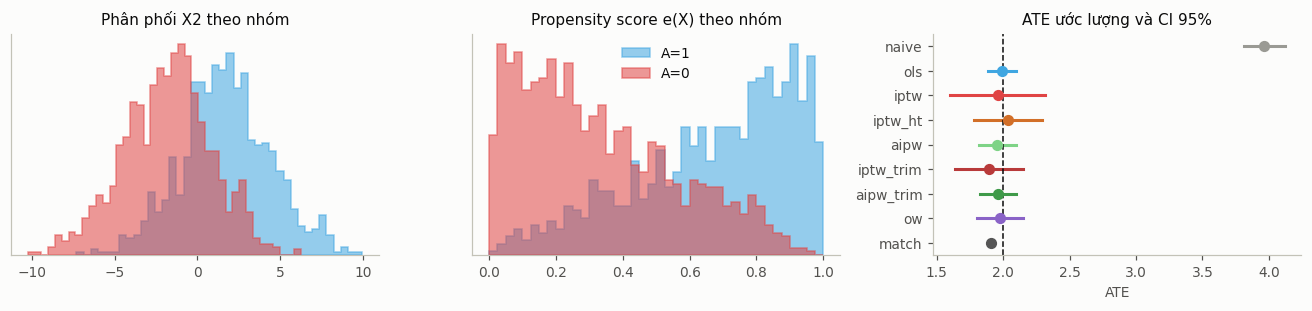

Balance trước / sau gán trọng số IPTW


,smd_before,vr_before,balanced_before,smd_after,vr_after,balanced_after
X1,0.367,0.993,False,-0.018,0.995,True
X2,1.328,1.034,False,0.101,1.238,False


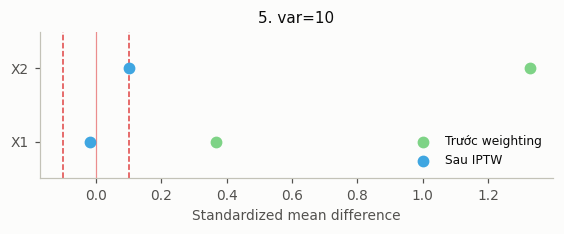

Cỡ mẫu hiệu dụng (ESS) của trọng số IPTW


,n,n_kept,ess,ess_ratio
toàn mẫu,2000,2000,923.398,0.462
treated (A=1),958,958,376.335,0.393
control (A=0),1042,1042,595.436,0.571


ATE ước lượng (thật = 2.0); iptw_trim/aipw_trim dùng trim=0.05, ow ước lượng ATO


,naive,ols,iptw,iptw_ht,aipw,iptw_trim,aipw_trim,ow,match
est,3.966,1.992,1.958,2.038,1.957,1.894,1.964,1.978,1.912
se,0.077,0.054,0.182,0.132,0.072,0.129,0.069,0.087,NaN
lo,3.815,1.885,1.602,1.781,1.816,1.640,1.829,1.807,NaN
hi,4.118,2.099,2.315,2.296,2.098,2.148,2.098,2.150,NaN
bias,1.966,-0.008,-0.042,0.038,-0.043,-0.106,-0.036,-0.022,-0.088


In [13]:
df5 = inspect_case("disp_v10")

**Nhận xét.** $v=10$: $e_{min}=0.007$, 0.6% quan sát có $e(X)\notin[0.01,0.99]$, ESS/n 0.46 (treated 0.39), max weight 42. SMD của X2 trước 1.33 và **sau IPTW 0.101, sát ngưỡng và bị đánh dấu không cân bằng**. SE của IPTW 0.182 (gấp ~3 lần baseline và gấp 3.4 lần OLS 0.054), CI 1.60–2.32. IPTW 1.96, AIPW 1.96, OLS 1.99, trim 1.89 (−0.11), matching 1.91; naive 3.97 (chệch gần +2). Đây chỉ là một mẫu; mức độ thực của các khác biệt này nằm ở phần 4.

### Tổng hợp Love plot của 5 kịch bản

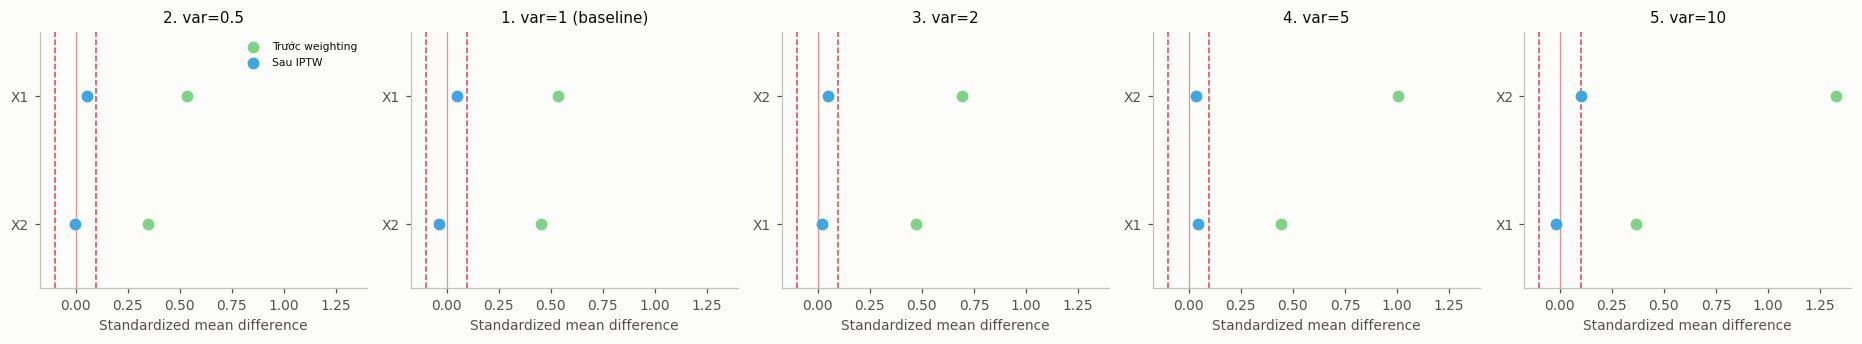

In [14]:
fig, axes = plt.subplots(1, 5, figsize=(17, 3.2), sharex=True)
for ax, k in zip(axes, NAMES):
    df = DispersionSimulation(k, n=N, seed=SEED, gamma=GAMMA).generate()
    love_plot(check_balance(df), ax=ax, title=SHORT[k])
    if ax.get_legend(): ax.get_legend().remove()
axes[0].legend(frameon=False, fontsize=7); fig.tight_layout(); plt.show()

**Nhận xét.** Khác nhóm 2, ở đây SMD của X2 **trước** weighting tăng theo phương sai (khoảng 0.35, 0.45, 0.69, 1.00, 1.33 từ $v=0.5$ đến 10), vì $X_2$ trải rộng làm $e(X)$ nhạy hơn với $X_2$ và hai nhóm tách xa nhau hơn. Sau IPTW mọi biến về dưới 0.1 cho tới $v=5$; ở $v=10$ X2 chạm 0.10. SMD của X1 gần như không đổi (0.37–0.53).

## 4. Mô phỏng lặp: 1000 lần $\times$ 5 kịch bản $\times$ $n\in\{500,2000\}$

Chỉ số: **bias**, **SD** (độ lệch chuẩn thực của ước lượng), **mean SE** (SE ước lượng trung bình; mean SE $\approx$ SD nghĩa là SE đáng tin), **RMSE**, **độ phủ CI 95%** (hợp lệ trong 0.95 $\pm$ 0.014), **độ rộng CI**, chẩn đoán overlap (ESS/n, max weight, $e(X)$ ngoài [0.01, 0.99], tỉ lệ trim) và **SMD** của $X_2$ trước/sau IPTW.

In [15]:
def run_mc(gamma, ns=NS, reps=REPS, names=NAMES):
    res = {}
    for n in ns:
        for k in names:
            sim = DispersionSimulation(k, n=n, seed=SEED, gamma=gamma)
            summ, dg, est = monte_carlo(sim, reps=reps, keep_raw=True)
            res[(n, k)] = {"summ": summ, "diag": dg, "est": est}
    return res
def table(res, n, metric, names=NAMES, cols=None):
    t = pd.DataFrame({SHORT[k]: res[(n, k)]["summ"][metric] for k in names}).T
    return t[cols or METHODS_ALL]
def diag_table(res, n, names=NAMES):
    return pd.DataFrame({SHORT[k]: res[(n, k)]["diag"] for k in names}).T
t0 = time.time(); R = run_mc(GAMMA); print(f"xong sau {time.time()-t0:.0f}s")

xong sau 52s


### 4.1 Chẩn đoán overlap (trung bình qua 1000 lần lặp)

In [16]:
for n in NS: print(f"n = {n}"); display(diag_table(R, n).round(3))

n = 500


,treated_rate,e_outside,max_weight,ess_ratio,trim_drop,match_discard
2. var=0.5,0.499,0.000,6.389,0.900,0.000,0.016
1. var=1 (baseline),0.499,0.000,7.680,0.868,0.000,0.020
3. var=2,0.499,0.000,10.123,0.810,0.002,0.025
4. var=5,0.500,0.000,18.094,0.654,0.020,0.043
5. var=10,0.500,0.005,31.708,0.480,0.081,0.071


n = 2000


,treated_rate,e_outside,max_weight,ess_ratio,trim_drop,match_discard
2. var=0.5,0.500,0.000,7.653,0.904,0.000,0.004
1. var=1 (baseline),0.500,0.000,9.471,0.873,0.000,0.005
3. var=2,0.499,0.000,13.420,0.813,0.001,0.008
4. var=5,0.499,0.000,26.384,0.648,0.017,0.015
5. var=10,0.500,0.006,53.283,0.447,0.077,0.029


**Nhận xét** 
- $\gamma=0.5$, $n=2000$:
    - Từ $v=0.5$ đến 10: ESS/n 0.90 -> 0.87 -> 0.81 -> 0.65 -> 0.45
    - max weight 7.7 -> 9.5 -> 13.4 -> 26.4 -> 53.3 (gấp 5.6 lần từ $v=1$ đến 10)
    - tỉ lệ trim 0.05 đạt 0 -> 0 -> 0.1% -> 1.7% -> 7.7%;
    - matching loại 0.4% -> 2.9%.
    - Treated luôn 50%. 
    - Tỉ lệ $e(X)\notin[0.01,0.99]$ chỉ khác 0 ở $v=10$ (0.6%) dù ESS đã mất hơn một nửa, nên ESS/n và tỉ lệ trim nhạy hơn để cảnh báo sớm. 
- Ở $n=500$ cùng xu hướng (ESS/n 0.48 ở $v=10$), max weight nhỏ hơn (31.7) vì ít quan sát hơn.

### 4.2 Bảng chỉ số, 4 phương pháp chính (n = 2000)

In [17]:
for m, t in [("bias", "Bias"), ("sd", "SD"), ("mean_se", "SE trung bình"), ("rmse", "RMSE"), ("coverage", "Độ phủ CI 95%"), ("ci_width", "Độ rộng CI 95%")]:
    print(t); display(table(R, 2000, m, cols=CORE).round(3))

Bias


,naive,ols,iptw,aipw
2. var=0.5,0.345,-0.001,-0.000,-0.000
1. var=1 (baseline),0.449,-0.002,-0.001,-0.001
3. var=2,0.645,-0.001,0.000,-0.000
4. var=5,1.157,0.002,0.003,0.001
5. var=10,1.851,0.001,0.008,0.000


SD


,naive,ols,iptw,aipw
2. var=0.5,0.052,0.046,0.047,0.047
1. var=1 (baseline),0.054,0.047,0.049,0.048
3. var=2,0.057,0.048,0.053,0.049
4. var=5,0.064,0.051,0.079,0.057
5. var=10,0.076,0.055,0.162,0.071


SE trung bình


,naive,ols,iptw,aipw
2. var=0.5,0.052,0.047,0.057,0.047
1. var=1 (baseline),0.054,0.047,0.061,0.048
3. var=2,0.057,0.048,0.071,0.050
4. var=5,0.066,0.051,0.108,0.056
5. var=10,0.076,0.054,0.187,0.068


... (2 outputs left out)

Độ phủ CI 95%


,naive,ols,iptw,aipw
2. var=0.5,0.0,0.954,0.977,0.958
1. var=1 (baseline),0.0,0.956,0.984,0.948
3. var=2,0.0,0.948,0.989,0.947
4. var=5,0.0,0.951,0.987,0.946
5. var=10,0.0,0.947,0.973,0.947


Độ rộng CI 95%


,naive,ols,iptw,aipw
2. var=0.5,0.203,0.183,0.222,0.184
1. var=1 (baseline),0.211,0.185,0.240,0.188
3. var=2,0.225,0.189,0.280,0.194
4. var=5,0.258,0.199,0.425,0.218
5. var=10,0.299,0.211,0.732,0.265


### 4.3 Bảng chỉ số, 4 phương pháp chính (n = 500)

In [18]:
for m, t in [("bias", "Bias"), ("sd", "SD"), ("mean_se", "SE trung bình"), ("rmse", "RMSE"), ("coverage", "Độ phủ CI 95%"), ("ci_width", "Độ rộng CI 95%")]:
    print(t); display(table(R, 500, m, cols=CORE).round(3))

Bias


,naive,ols,iptw,aipw
2. var=0.5,0.345,-0.001,0.000,-0.001
1. var=1 (baseline),0.447,-0.002,-0.000,-0.002
3. var=2,0.639,-0.006,-0.001,-0.005
4. var=5,1.154,-0.004,0.005,-0.007
5. var=10,1.849,-0.002,0.029,-0.007


SD


,naive,ols,iptw,aipw
2. var=0.5,0.106,0.097,0.099,0.097
1. var=1 (baseline),0.108,0.095,0.100,0.097
3. var=2,0.114,0.095,0.105,0.098
4. var=5,0.133,0.100,0.149,0.109
5. var=10,0.156,0.106,0.285,0.137


SE trung bình


,naive,ols,iptw,aipw
2. var=0.5,0.104,0.093,0.113,0.094
1. var=1 (baseline),0.108,0.095,0.123,0.096
3. var=2,0.115,0.097,0.141,0.099
4. var=5,0.132,0.102,0.209,0.110
5. var=10,0.153,0.108,0.328,0.131


... (2 outputs left out)

Độ phủ CI 95%


,naive,ols,iptw,aipw
2. var=0.5,0.083,0.939,0.973,0.944
1. var=1 (baseline),0.008,0.954,0.985,0.952
3. var=2,0.001,0.949,0.986,0.946
4. var=5,0.000,0.948,0.991,0.952
5. var=10,0.000,0.952,0.968,0.941


Độ rộng CI 95%


,naive,ols,iptw,aipw
2. var=0.5,0.407,0.366,0.444,0.368
1. var=1 (baseline),0.423,0.371,0.480,0.375
3. var=2,0.451,0.379,0.554,0.388
4. var=5,0.517,0.399,0.818,0.432
5. var=10,0.598,0.423,1.286,0.514


### 4.4 Trực quan: Bias $\times$ SD $\times$ RMSE

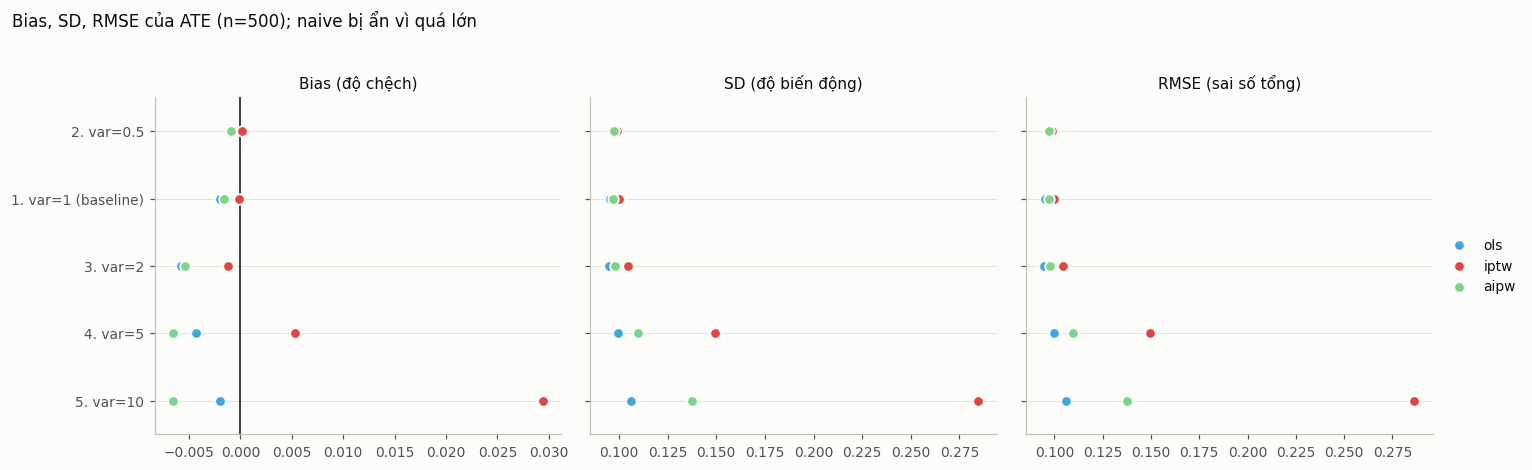

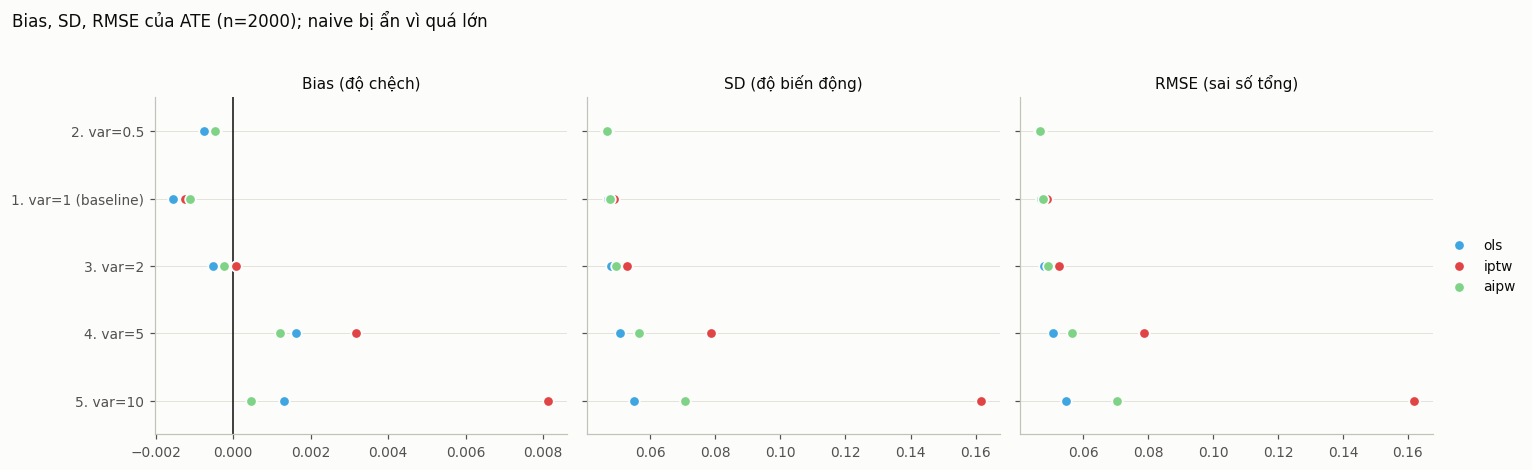

In [19]:
def plot_mc(res, n, methods=("ols", "iptw", "aipw"), names=NAMES, title=None):
    panels = [("Bias (độ chệch)", table(res, n, "bias")), ("SD (độ biến động)", table(res, n, "sd")), ("RMSE (sai số tổng)", table(res, n, "rmse"))]
    y = np.arange(len(names))
    fig, axes = plt.subplots(1, 3, figsize=(14, 0.5 * len(names) + 1.8), sharey=True)
    for ax, (ttl, tab) in zip(axes, panels):
        for yi in y: ax.axhline(yi, color="#e1e0d9", lw=0.6, zorder=1)
        for m in methods:
            ax.scatter(tab[m], y, s=48, color=MCOL[m], label=m, zorder=3, edgecolor="#fcfcfb", linewidth=1.2)
        if ttl.startswith("Bias"): ax.axvline(0, color=INK, lw=1)
        ax.set_title(ttl); ax.grid(axis="y", visible=False)
    axes[0].set_yticks(y); axes[0].set_yticklabels(tab.index); axes[0].set_ylim(len(names) - 0.5, -0.5)
    axes[2].legend(frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5))
    fig.suptitle(title or f"Bias, SD, RMSE của ATE (n={n}); naive bị ẩn vì quá lớn", x=0.01, ha="left", fontsize=11)
    fig.tight_layout(rect=[0, 0, 1, 0.95]); plt.show()
for n in NS: plot_mc(R, n)

**Nhận xét ($\gamma=0.5$).**
- **Bias:** OLS, IPTW, AIPW gần như bằng 0 ở mọi phương sai ($|\text{bias}|\le0.008$ với $n=2000$; IPTW 0.029 ở $v=10$, $n=500$). Phương sai lớn **không gây chệch** cho các phương pháp có hiệu chỉnh. Naive chệch tăng rất mạnh: 0.35, 0.45, 0.65, 1.16, 1.85 vì $X_2$ giải thích ngày càng nhiều biến thiên của cả $A$ và $Y$.
- **Phương sai ước lượng:** từ $v=1$ đến 10 (n=2000) SD của OLS 0.047 → 0.055 (+17%), AIPW 0.048 → 0.071 (gấp 1.5), IPTW 0.049 → 0.162 (gấp 3.3). RMSE gần như trùng SD vì bias không đáng kể. Với $n=500$ cùng xu hướng (IPTW 0.100 → 0.285).
- Đây là **variance explosion có kiểm soát**: IPTW chịu hậu quả nặng nhất, AIPW nhẹ hơn nhiều, OLS gần như không bị ảnh hưởng.

### 4.5 SE có đáng tin không, độ phủ và độ rộng CI

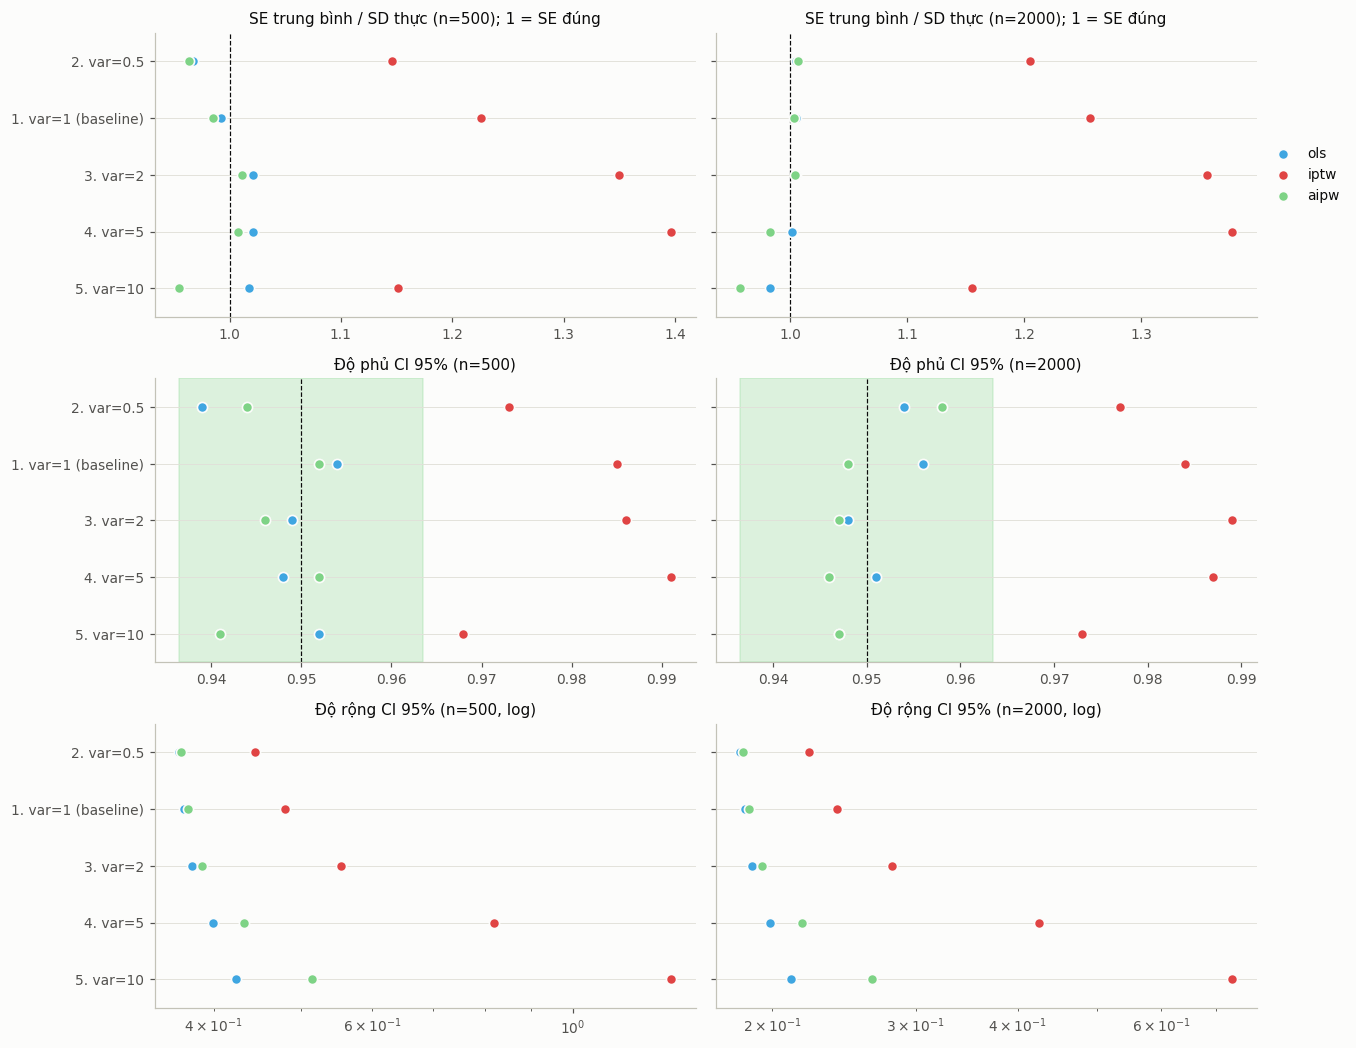

In [20]:
def plot_se_cov(res, ns=NS, methods=("ols", "iptw", "aipw"), reps=REPS, names=NAMES):
    half = 1.96 * np.sqrt(0.95 * 0.05 / reps)
    fig, axes = plt.subplots(3, len(ns), figsize=(6.2 * len(ns), 9.6), sharey="row")
    y = np.arange(len(names))
    for j, n in enumerate(ns):
        ratio = table(res, n, "mean_se") / table(res, n, "sd")
        panels = [(axes[0, j], ratio, f"SE trung bình / SD thực (n={n}); 1 = SE đúng"),
                  (axes[1, j], table(res, n, "coverage"), f"Độ phủ CI 95% (n={n})"),
                  (axes[2, j], table(res, n, "ci_width"), f"Độ rộng CI 95% (n={n}, log)")]
        for ax, tab, ttl in panels:
            for yi in y: ax.axhline(yi, color="#e1e0d9", lw=0.6, zorder=1)
            for m in methods: ax.scatter(tab[m], y, s=44, color=MCOL[m], label=m, zorder=3, edgecolor="#fcfcfb", linewidth=1.1)
            ax.set_title(ttl); ax.set_yticks(y); ax.set_yticklabels(tab.index); ax.set_ylim(len(names) - 0.5, -0.5); ax.grid(axis="y", visible=False)
        axes[0, j].axvline(1, color=INK, lw=0.8, ls="--")
        axes[1, j].axvspan(0.95 - half, 0.95 + half, color="#7ED386", alpha=0.25, zorder=0); axes[1, j].axvline(0.95, color=INK, lw=0.8, ls="--")
        axes[2, j].set_xscale("log")
    axes[0, -1].legend(frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5))
    fig.tight_layout(); plt.show()
plot_se_cov(R)

**Nhận xét ($\gamma=0.5$, $n=2000$).**
- **SE của OLS và AIPW đáng tin** (SE/SD 0.96–1.02) và độ phủ 0.947–0.958 ở cả 5 kịch bản kể cả $v=10$. **SE của IPTW bảo thủ** (SE/SD 1.15–1.37 do bỏ qua sai số ước lượng PS) nên độ phủ 0.97–0.99.
- **Độ rộng CI** từ $v=1$ đến 10: OLS 0.185 → 0.211 (+14%), AIPW 0.188 → 0.265 (+41%), IPTW 0.240 → 0.732 (gấp 3.0). Ở $v=10$ CI của IPTW rộng gấp 3.5 lần OLS.
- Ở $\gamma=0.5$ CI vẫn hợp lệ trên toàn dải; điều kiện làm CI mất ý nghĩa nằm ở phần 5.

### 4.6 Phân phối của ATE ước lượng qua 1000 lần lặp

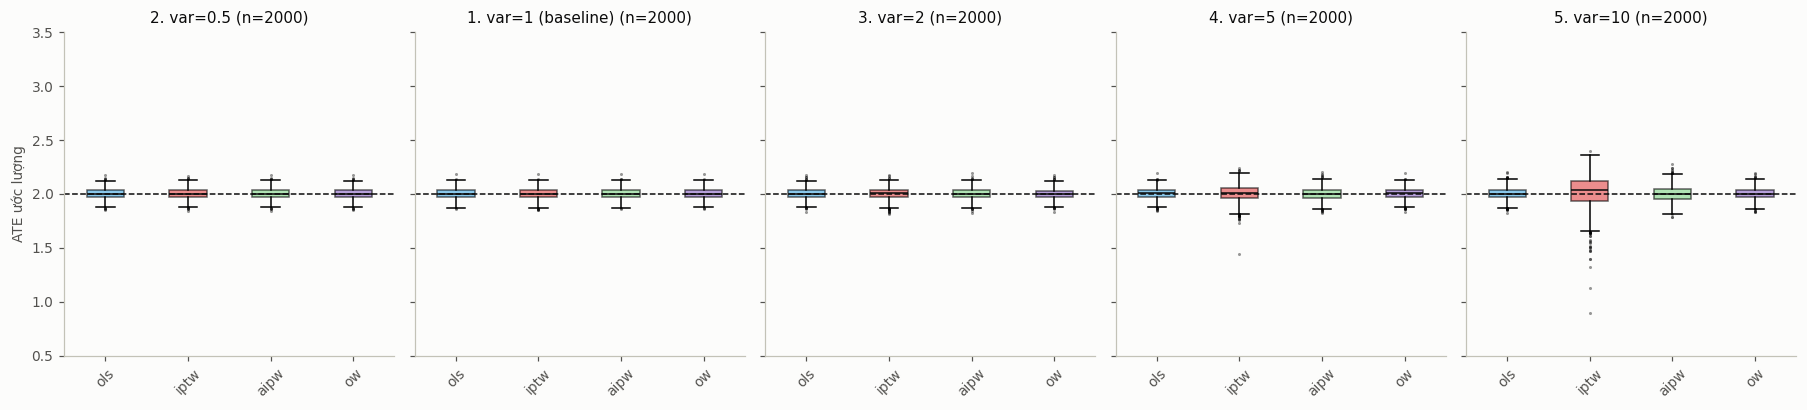

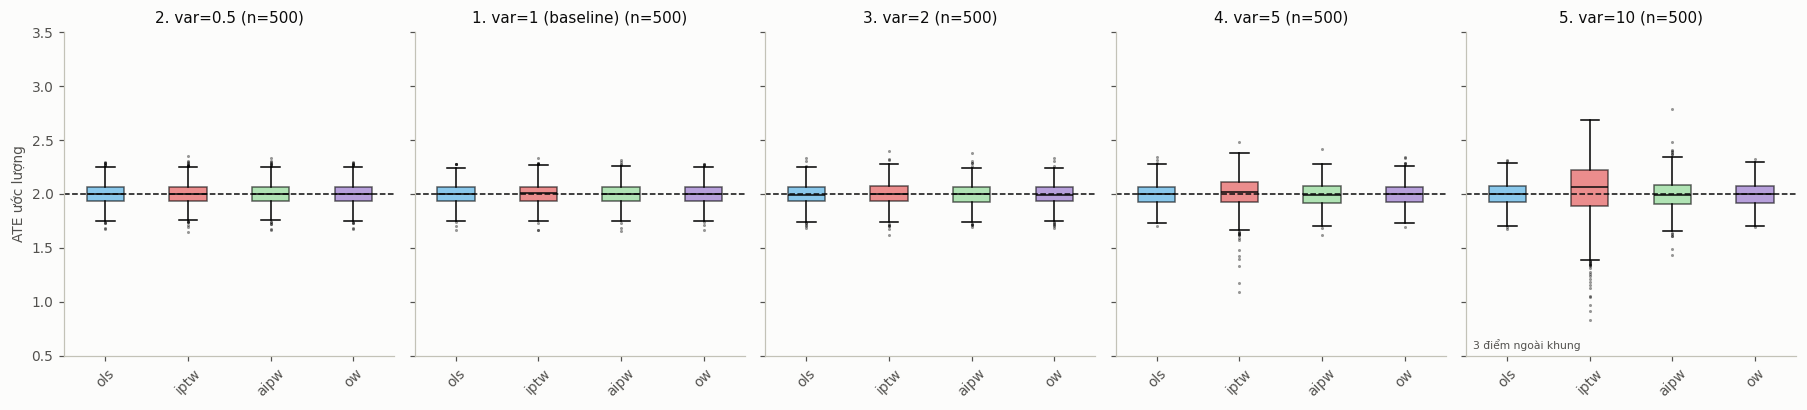

In [21]:
def plot_box(res, n=2000, names=NAMES, methods=("ols", "iptw", "aipw", "ow"), truth=2.0, half=1.5):
    fig, axes = plt.subplots(1, len(names), figsize=(3.3 * len(names), 3.8), sharey=True)
    for ax, k in zip(axes, names):
        est = res[(n, k)]["est"][list(methods)]
        bp = ax.boxplot([est[m].dropna() for m in methods], showfliers=True, patch_artist=True,
                        flierprops=dict(marker=".", ms=2, alpha=0.4), medianprops=dict(color=INK))
        ax.set_xticks(range(1, len(methods) + 1)); ax.set_xticklabels(methods)
        for patch, m in zip(bp["boxes"], methods): patch.set_facecolor(MCOL[m]); patch.set_alpha(0.6)
        ax.axhline(truth, color=INK, ls="--", lw=1); ax.set_title(f"{SHORT[k]} (n={n})")
        ax.set_ylim(truth - half, truth + half)
        out = int(((est < truth - half) | (est > truth + half)).to_numpy().sum())
        if out: ax.text(0.02, 0.02, f"{out} điểm ngoài khung", transform=ax.transAxes, fontsize=7, color="#52514e")
        ax.tick_params(axis="x", rotation=45)
    axes[0].set_ylabel("ATE ước lượng"); fig.tight_layout(); plt.show()
plot_box(R, 2000); plot_box(R, 500)

**Nhận xét ($\gamma=0.5$).** Mọi hộp đều tâm tại 2. OLS, AIPW, OW hẹp gần như không đổi; hộp IPTW rộng dần và từ $v=5$ có đuôi dưới dài, tới $v=10$ nằm trong khoảng $\approx$ 0.9 - 2.4 với nhiều điểm ngoại lai về phía thấp. Sai số đến từ vài lần lặp có trọng số rất lớn chứ không phải chệch.

### 4.7 SMD của X2 trước và sau IPTW (trung bình 200 lần lặp)

,|SMD| trước,|SMD| sau IPTW,VR sau (TB),tỉ lệ cân bằng sau
2. var=0.5,0.330,0.038,0.997,0.97
1. var=1 (baseline),0.462,0.040,0.994,0.96
3. var=2,0.642,0.050,0.995,0.88
4. var=5,0.959,0.062,1.011,0.79
5. var=10,1.262,0.097,1.014,0.57


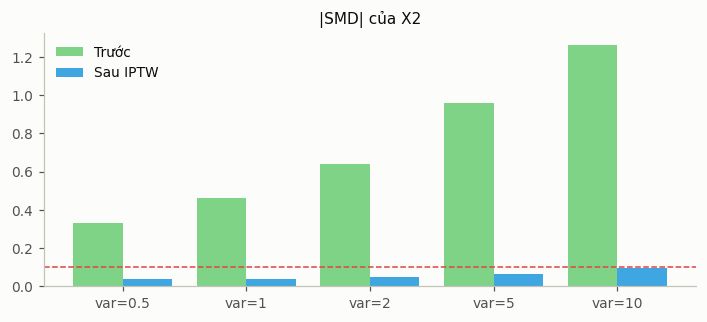

In [22]:
def smd_mc(name, n=N, gamma=GAMMA, reps=200):
    sim = DispersionSimulation(name, n=n, seed=SEED, gamma=gamma); rows = []
    for _ in range(reps):
        t = check_balance(sim.generate())
        rows.append([t.loc["X2", "smd_before"], t.loc["X2", "smd_after"], t.loc["X2", "vr_after"], float(t.loc["X2", "balanced_after"])])
    r = np.array(rows)
    return {"|SMD| trước": np.abs(r[:, 0]).mean(), "|SMD| sau IPTW": np.abs(r[:, 1]).mean(), "VR sau (TB)": np.nanmean(r[:, 2]), "tỉ lệ cân bằng sau": r[:, 3].mean()}
SMD = pd.DataFrame({SHORT[k]: smd_mc(k) for k in NAMES}).T
display(SMD.round(3))
fig, ax = plt.subplots(figsize=(6.5, 3.0)); x = np.arange(len(NAMES))
ax.bar(x - 0.2, SMD["|SMD| trước"], 0.4, color=GREEN, label="Trước"); ax.bar(x + 0.2, SMD["|SMD| sau IPTW"], 0.4, color=BLUE, label="Sau IPTW")
ax.axhline(0.1, color=RED, ls="--", lw=1); ax.set_xticks(x); ax.set_xticklabels([SHORT[k].split(" ")[1] for k in NAMES]); ax.set_title("|SMD| của X2"); ax.legend(frameon=False)
fig.tight_layout(); plt.show()

**Nhận xét.** |SMD| của X2 trước weighting tăng theo phương sai (0.33 $\rightarrow$ 1.26), còn sau IPTW chỉ 0.04 $\rightarrow$ 0.097. Tỉ lệ lần lặp đạt cân bằng (|SMD| < 0.1 và VR trong [0.5, 2]) giảm 0.97 $\rightarrow$ 0.96 $\rightarrow$ 0.88 $\rightarrow$ 0.79 $\rightarrow$ 0.57: ở $v=10$ gần một nửa số mẫu **không** cân bằng được dù |SMD| trung bình chỉ vừa chạm ngưỡng. VR sau weighting $\approx$ 1.

## 5. Độ nhạy theo độ mạnh confounding ($\gamma=1$)

Với $\gamma=0.5$ phương sai lớn nhất ($v=10$) mới làm $\text{var}(\gamma'X)=2.75$. Với $\gamma=1$ con số này gấp 4 lần (11), tương ứng $e(X)$ cực đoan hơn nhiều. Chạy lại toàn bộ với $\gamma=(1,1)$.

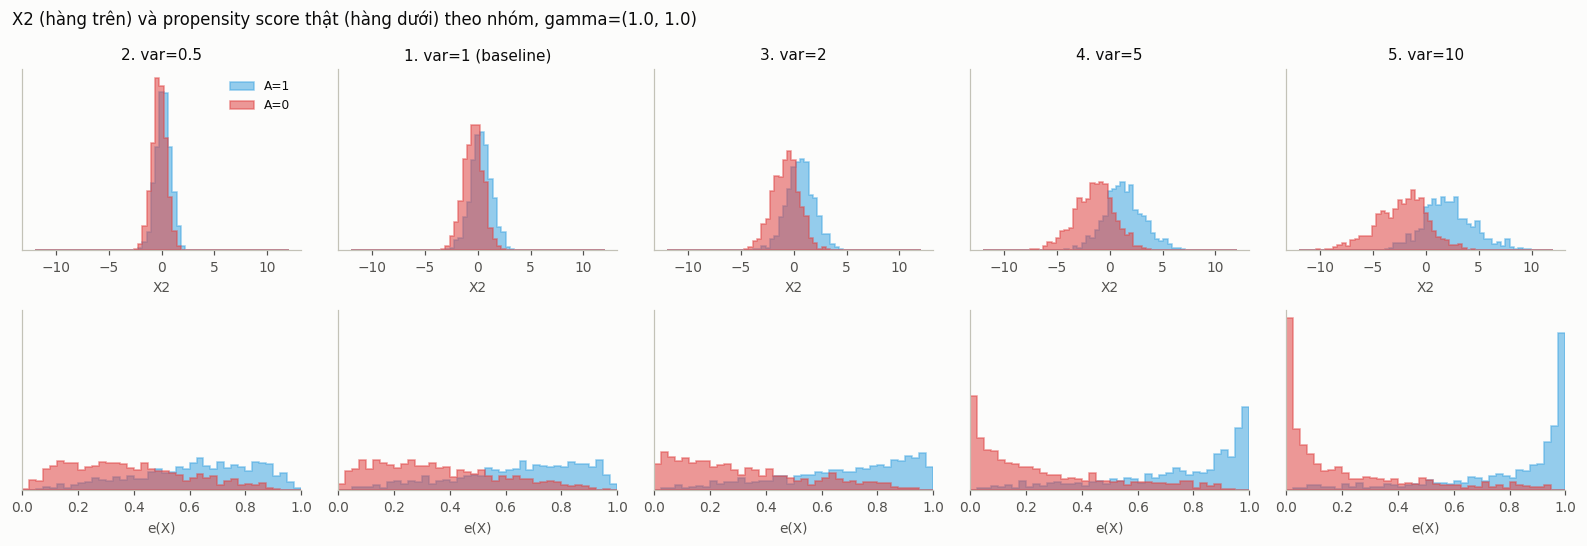

xong sau 58s
n = 500: chẩn đoán overlap


,treated_rate,e_outside,max_weight,ess_ratio,trim_drop,match_discard
2. var=0.5,0.499,0.000,18.305,0.654,0.020,0.043
1. var=1 (baseline),0.499,0.001,23.841,0.570,0.042,0.055
3. var=2,0.499,0.008,36.098,0.451,0.094,0.077
4. var=5,0.500,0.061,66.022,0.294,0.235,0.140
5. var=10,0.500,0.166,116.863,0.213,0.380,0.220


n = 2000: chẩn đoán overlap


,treated_rate,e_outside,max_weight,ess_ratio,trim_drop,match_discard
2. var=0.5,0.499,0.000,26.807,0.647,0.017,0.015
1. var=1 (baseline),0.499,0.001,36.798,0.556,0.038,0.020
3. var=2,0.499,0.008,59.824,0.419,0.090,0.031
4. var=5,0.499,0.061,146.441,0.222,0.230,0.068
5. var=10,0.499,0.166,268.720,0.136,0.377,0.127


Bias (gamma=1, n=2000)


,naive,ols,iptw,aipw
2. var=0.5,0.578,0.000,0.002,0.001
1. var=1 (baseline),0.725,-0.001,0.001,0.000
3. var=2,0.987,0.001,0.006,0.001
4. var=5,1.599,0.003,0.029,-0.000
5. var=10,2.342,0.002,0.159,-0.012


... (6 outputs left out)

Độ phủ CI 95% (gamma=1, n=2000)


,naive,ols,iptw,aipw
2. var=0.5,0.0,0.948,0.978,0.959
1. var=1 (baseline),0.0,0.960,0.975,0.947
3. var=2,0.0,0.957,0.958,0.956
4. var=5,0.0,0.956,0.862,0.959
5. var=10,0.0,0.955,0.693,0.948


Độ rộng CI 95% (gamma=1, n=2000)


,naive,ols,iptw,aipw
2. var=0.5,0.199,0.199,0.285,0.219
1. var=1 (baseline),0.205,0.204,0.339,0.236
3. var=2,0.215,0.213,0.462,0.274
4. var=5,0.239,0.231,0.877,0.426
5. var=10,0.271,0.247,1.373,0.656


In [23]:
G2 = (1.0, 1.0)
overview_grid(gamma=G2)
t0 = time.time(); R2 = run_mc(G2); print(f"xong sau {time.time()-t0:.0f}s")
for n in NS: print(f"n = {n}: chẩn đoán overlap"); display(diag_table(R2, n).round(3))
for m, t in [("bias", "Bias"), ("sd", "SD"), ("mean_se", "SE trung bình"), ("rmse", "RMSE"), ("coverage", "Độ phủ CI 95%"), ("ci_width", "Độ rộng CI 95%")]:
    print(f"{t} (gamma=1, n=2000)"); display(table(R2, 2000, m, cols=CORE).round(3))

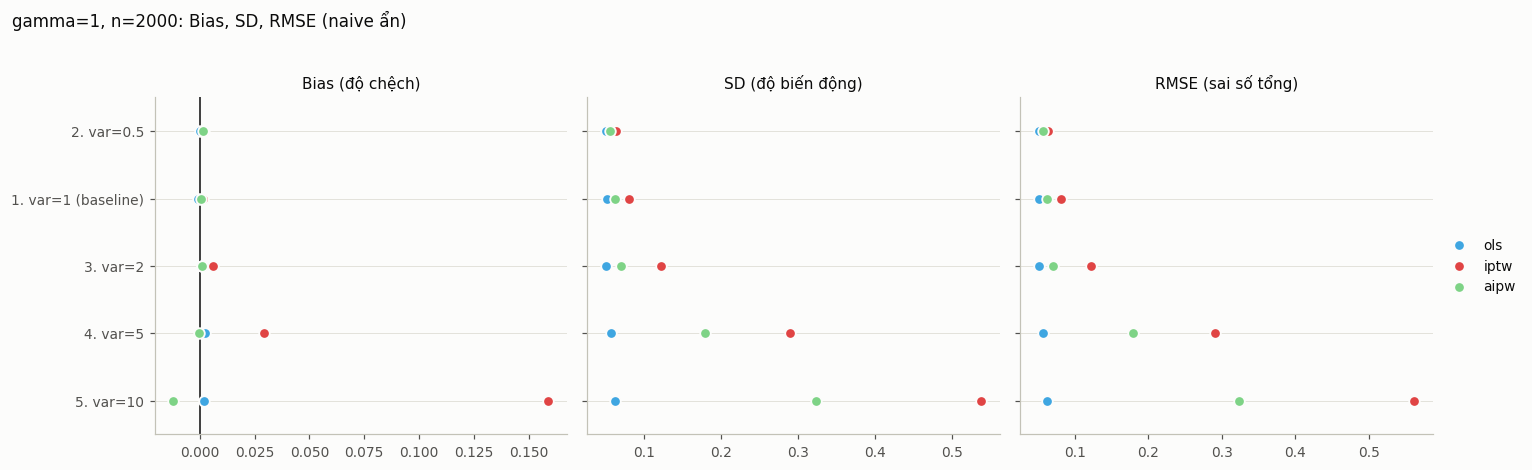

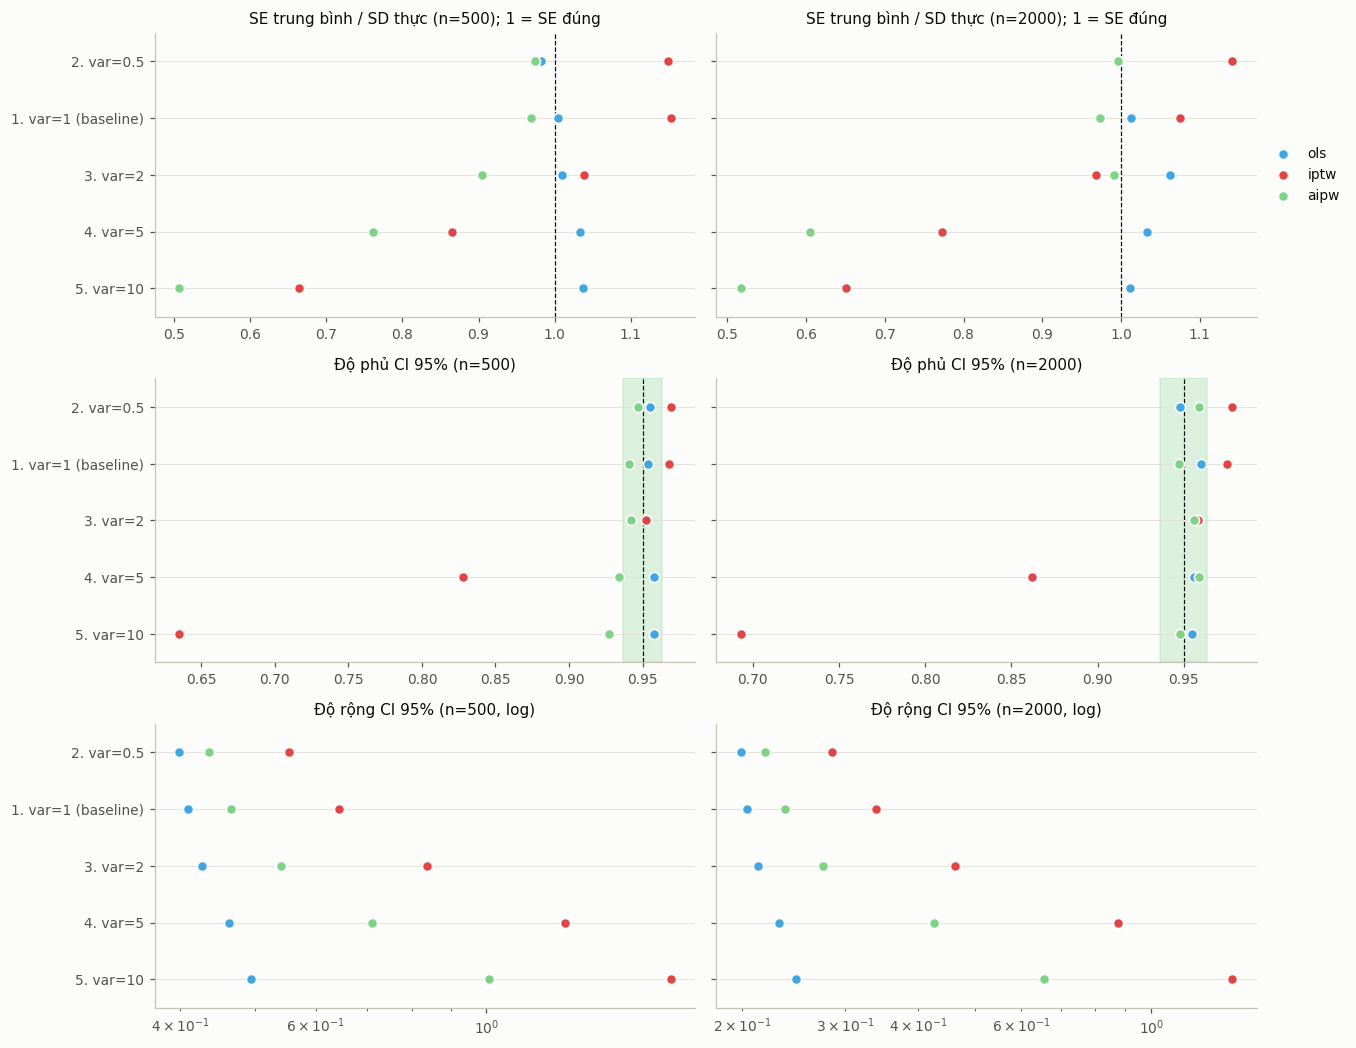

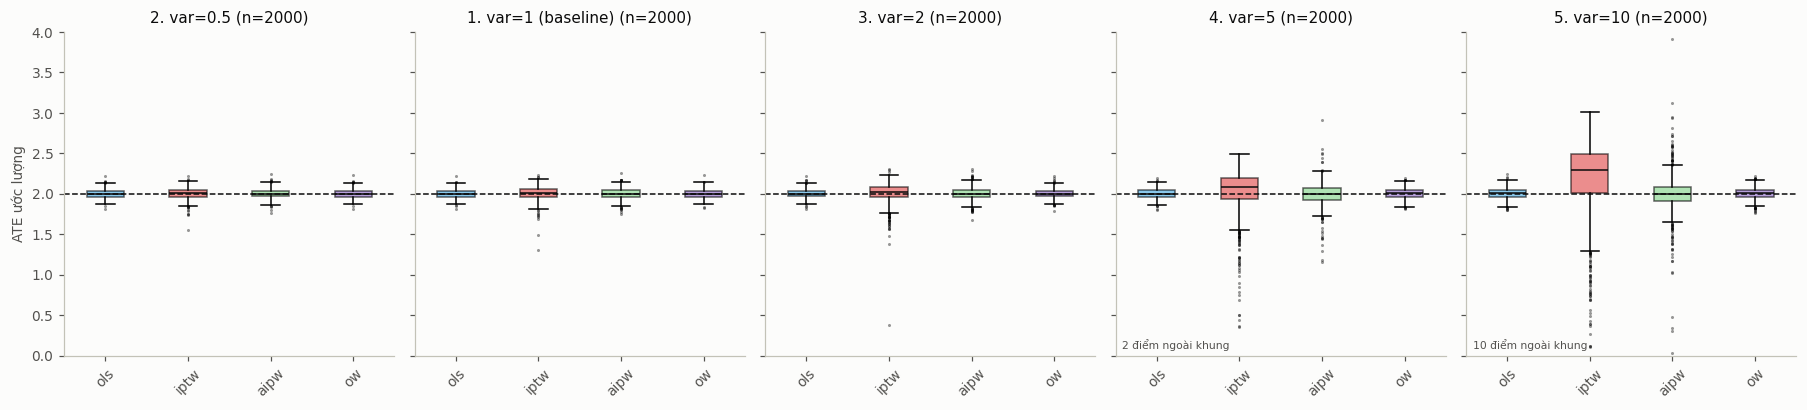

Tỉ số RMSE(n=500)/RMSE(n=2000), gamma=1 (~=2 nếu ổn định)


,naive,ols,iptw,iptw_ht,aipw,iptw_trim,aipw_trim,ow,match
2. var=0.5,1.01,2.04,1.93,2.05,2.04,2.06,2.06,2.04,1.97
1. var=1 (baseline),1.01,2.02,1.77,1.96,1.98,2.08,2.08,2.02,1.96
3. var=2,1.00,2.11,1.69,1.96,2.16,2.07,2.12,2.12,1.92
4. var=5,1.00,2.00,1.32,0.99,1.33,2.02,2.08,2.04,1.74
5. var=10,1.00,1.95,1.31,1.05,1.57,1.92,2.00,1.97,1.60


In [24]:
plot_mc(R2, 2000, title="gamma=1, n=2000: Bias, SD, RMSE (naive ẩn)")
plot_se_cov(R2)
plot_box(R2, 2000, half=2.0)
print("Tỉ số RMSE(n=500)/RMSE(n=2000), gamma=1 (~=2 nếu ổn định)")
display((table(R2, 500, "rmse") / table(R2, 2000, "rmse")).round(2))

**Nhận xét ($\gamma=1$, $n=2000$).**
- **Overlap:** từ $v=1$ đến 10, $e(X)$ ngoài biên 0.1% $\rightarrow$ 16.6%, ESS/n 0.56 $\rightarrow$ 0.14 ($\approx$ 270 quan sát hiệu dụng), max weight 37 $\rightarrow$ 269, trim 0.05 loại 4% $\rightarrow$ 38%, matching loại 1.5% $\rightarrow$ 12.7% (22% ở $n=500$).
- **Bias:** IPTW 0.029 ($v=5$), 0.159 ($v=10$); AIPW $\approx$ 0 (−0.012); OLS 0.002.
- **RMSE ở $v=10$:** OLS 0.062 < AIPW 0.324 < IPTW 0.561. IPTW gấp ~9 lần OLS và SD của IPTW tăng 6.7 lần so với baseline (0.080 $\rightarrow$ 0.538).
- **Độ phủ:** IPTW 0.862 ($v=5$) và 0.693 ($v=10$), tức CI mất ý nghĩa. OLS, AIPW giữ 0.95–0.96. SE trung bình của IPTW nhỏ hơn SD thật (0.350 so với 0.538 ở $v=10$), AIPW cũng vậy (0.167 so với 0.324); AIPW vẫn phủ $\approx$ 0.95, gợi ý SD bị kéo lên bởi vài lần lặp cực đoan chứ phần lớn lần lặp có sai số nhỏ hơn. Phân phối IPTW lệch (box plot: trung vị $\approx$ 2.3 và đuôi dưới kéo dài).
- **Độ hội tụ:** tỉ số RMSE (n=500/n=2000) của IPTW chỉ 1.31–1.32 và AIPW 1.33–1.57 ở $v=5$–10 (so với $\approx$ 2 nếu ổn định): tăng $n$ không bù được mất ESS ở đuôi nặng. OLS, OW, trimming vẫn $\approx$ 2.
- OLS tốt nhất vì mô hình outcome trong DGP đúng.

## 6. Cách xử lý: trimming, clipping, overlap weighting

Trên kịch bản cực đoan nhất ($v=10$) so sánh cách xử lý $e(X)$ cực đoan, với $\gamma=0.5$ và $\gamma=1$, $n=2000$, 500 lần lặp:
trimming (`drop`, 0.01/0.05/0.10), clipping (`clip`), overlap weighting (ATO). Do $\tau$ đồng nhất, mọi estimand đều bằng 2 nên bias so với 2 là công bằng; khi $\tau(X)$ thay đổi, ATE, ATE vùng overlap và ATO sẽ khác nhau.

In [25]:
def treat_mc(name, gamma, n=N, reps=500, seed=SEED):
    sim = DispersionSimulation(name, n=n, seed=seed, gamma=gamma)
    configs = [("không xử lý", None, "drop"), ("trim 0.01", 0.01, "drop"), ("trim 0.05", 0.05, "drop"),
               ("trim 0.10", 0.10, "drop"), ("clip 0.05", 0.05, "clip"), ("clip 0.10", 0.10, "clip")]
    rec = {c[0]: [] for c in configs}; rec["OW (ATO)"] = []; kept = {c[0]: [] for c in configs}
    for _ in range(reps):
        df = sim.generate(); e_hat = estimate_ps(df, ["X1", "X2"])
        for lab, t, mode in configs:
            try:
                r = estimate_all(df, use_estimated_ps=True, trim=t, trim_mode=mode); rec[lab].append((r["iptw"], r["aipw"]))
            except ValueError:
                rec[lab].append((np.nan, np.nan))
            kept[lab].append(1.0 if (t is None or mode == "clip") else overlap_mask(e_hat, t).mean())
        rec["OW (ATO)"].append((estimate_with_se(df, methods=["ow"]).loc["ow", "est"],) * 2)
    rows = []
    for lab, v in rec.items():
        v = np.array(v, float)
        for j, m in enumerate(("iptw", "aipw")):
            if lab.startswith("OW") and m == "aipw": continue
            x = v[:, j]
            rows.append({"cách xử lý": lab, "estimator": "ow" if lab.startswith("OW") else m, "bias": np.nanmean(x) - sim.ate,
                         "sd": np.nanstd(x, ddof=1), "rmse": np.sqrt(np.nanmean((x - sim.ate) ** 2)),
                         "tỉ lệ giữ lại": np.mean(kept[lab]) if lab in kept else 1.0, "n_fail": int(np.isnan(x).sum())})
    return pd.DataFrame(rows)
TR = {g: treat_mc("disp_v10", (g, g)) for g in (0.5, 1.0)}
for g in TR: print(f"var=10, gamma={g}"); display(TR[g].round(3))

var=10, gamma=0.5


,cách xử lý,estimator,bias,sd,rmse,tỉ lệ giữ lại,n_fail
0,không xử lý,iptw,0.005,0.171,0.171,1.000,0
1,không xử lý,aipw,0.002,0.071,0.071,1.000,0
2,trim 0.01,iptw,0.007,0.134,0.134,0.994,0
3,trim 0.01,aipw,0.001,0.068,0.068,0.994,0
4,trim 0.05,iptw,0.003,0.080,0.080,0.923,0
5,trim 0.05,aipw,0.003,0.059,0.059,0.923,0
6,trim 0.10,iptw,0.004,0.076,0.076,0.814,0
7,trim 0.10,aipw,0.004,0.059,0.059,0.814,0
8,clip 0.05,iptw,0.134,0.090,0.161,1.000,0
9,clip 0.05,aipw,0.002,0.063,0.063,1.000,0


var=10, gamma=1.0


,cách xử lý,estimator,bias,sd,rmse,tỉ lệ giữ lại,n_fail
0,không xử lý,iptw,0.150,0.567,0.586,1.000,0
1,không xử lý,aipw,-0.019,0.393,0.393,1.000,0
2,trim 0.01,iptw,0.002,0.157,0.156,0.832,0
3,trim 0.01,aipw,-0.000,0.101,0.101,0.832,0
4,trim 0.05,iptw,0.007,0.097,0.097,0.623,0
5,trim 0.05,aipw,0.004,0.080,0.080,0.623,0
6,trim 0.10,iptw,0.008,0.089,0.089,0.490,0
7,trim 0.10,aipw,0.007,0.078,0.078,0.490,0
8,clip 0.05,iptw,0.802,0.107,0.809,1.000,0
9,clip 0.05,aipw,0.002,0.075,0.074,1.000,0


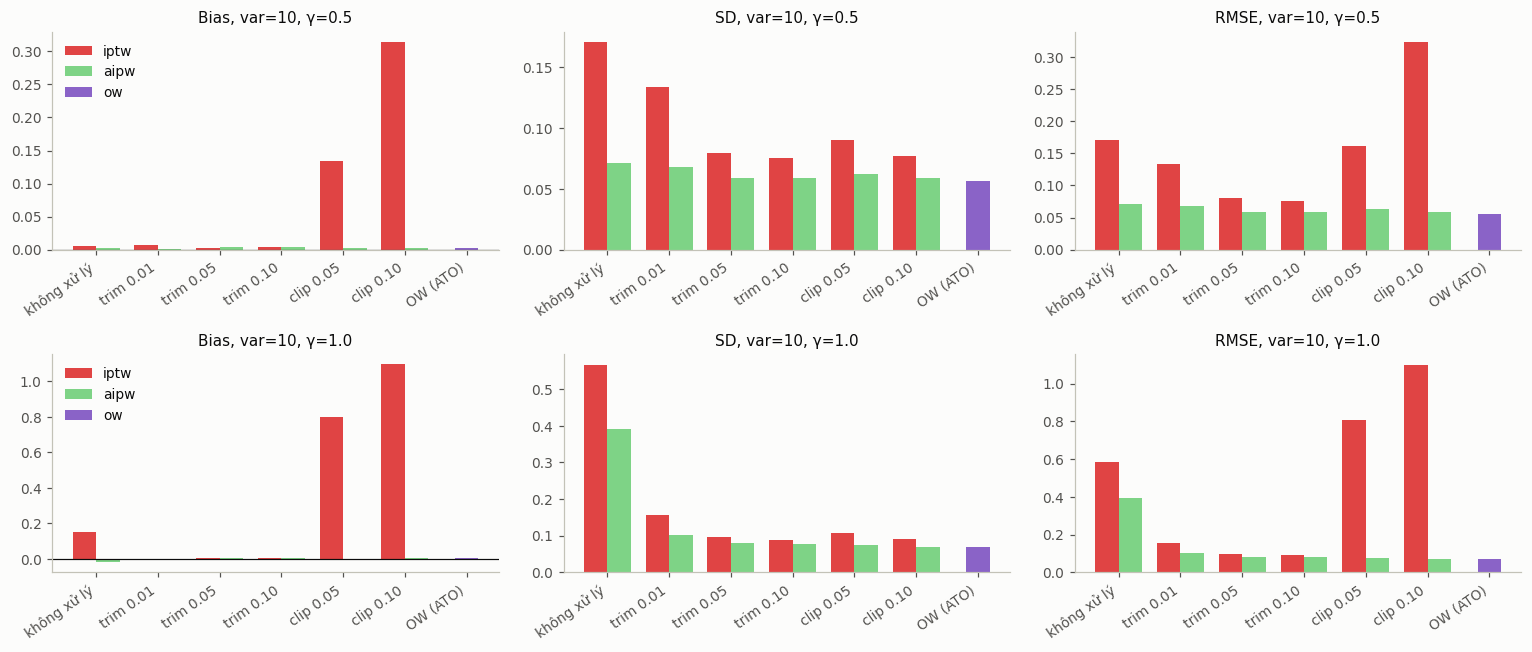

In [26]:
fig, axes = plt.subplots(2, 3, figsize=(14, 6.0))
for r, g in enumerate((0.5, 1.0)):
    d = TR[g]; labels = list(dict.fromkeys(d["cách xử lý"])); x = np.arange(len(labels)); w = 0.38
    for ax, c, t in zip(axes[r], ("bias", "sd", "rmse"), ("Bias", "SD", "RMSE")):
        for i, (m, col) in enumerate((("iptw", RED), ("aipw", GREEN))):
            ax.bar(x + (i - 0.5) * w, d[d["estimator"] == m].set_index("cách xử lý").reindex(labels)[c], w, color=col, label=m)
        ax.bar(labels.index("OW (ATO)"), d[d["estimator"] == "ow"][c].iloc[0], w, color=PURPLE, label="ow")
        ax.set_xticks(x); ax.set_xticklabels(labels, rotation=35, ha="right"); ax.set_title(f"{t}, var=10, γ={g}")
        if c == "bias": ax.axhline(0, color=INK, lw=0.8)
    axes[r, 0].legend(frameon=False)
fig.tight_layout(); plt.show()

**Nhận xét ($v=10$).**
- **$\gamma=0.5$:** trim 0.05 (giữ 92%) giảm RMSE IPTW từ 0.171 xuống 0.080, AIPW 0.071 → 0.059; trim 0.10 (giữ 81%) tương tự. **Clipping làm IPTW chệch** +0.134 (clip 0.05) và +0.314 (clip 0.10); AIPW không bị ảnh hưởng. OW có RMSE thấp nhất, 0.056.
- **$\gamma=1$:** không xử lý, IPTW RMSE 0.586, AIPW 0.393. **Trimming có hiệu quả tốt hơn nhiều so với nhóm 2**: trim 0.05 (giữ 62%) giảm RMSE IPTW còn 0.097, AIPW 0.080; trim 0.10 (giữ 49%) 0.089 và 0.078; không có lần thất bại. Lý do: phương sai lớn tạo ra các điểm cực đoan *ở đuôi*, trong khi lõi của phân phối vẫn còn nhiều quan sát chồng lấp để giữ lại. **Clipping tệ nhất với IPTW** (bias +0.80 và +1.10, RMSE 0.81 và 1.10), AIPW sau clipping ổn (RMSE 0.07). OW: bias 0.005, RMSE 0.069, ngang AIPW trim và không cần ngưỡng.
- **Lưu ý estimand.** Trimming và OW trả lời cho quần thể có overlap, không phải toàn bộ ATE. Ở đây $\tau$ đồng nhất nên so với 2 là công bằng.

## 7. Kết luận và quy trình đề xuất

### Trả lời câu hỏi nghiên cứu

Phương sai lớn **không làm chệch** các phương pháp có hiệu chỉnh; nó làm **phình phương sai** của IPTW (và AIPW ở mức nhẹ hơn), và đến một ngưỡng thì làm CI của IPTW mất ý nghĩa. Mức độ phụ thuộc vào cả $v$ lẫn độ mạnh confounding $\gamma$ (đại lượng liên quan là phương sai của tổ hợp tuyến tính $\gamma_1^2+\gamma_2^2v$).

| Mức | Điều kiện | Quan sát (n=2000) |
|---|---|---|
| Ổn định | $v\le2$ ($\gamma=0.5$) | ESS/n ≥ 0.81, max weight ≤ 13; mọi phương pháp ngoài naive gần như baseline; SD IPTW tăng ≤ 8% |
| Phình phương sai | $v=5$–10 ($\gamma=0.5$); $v=2$–5 ($\gamma=1$) | ESS/n 0.45–0.65; SD IPTW gấp 1.6–3.3 lần baseline, CI IPTW rộng gấp ~3 ở $v=10$; vẫn không chệch, CI hợp lệ (phủ ≥ 0.95, IPTW bảo thủ) |
| CI IPTW mất ý nghĩa | $v\ge15$ ($\gamma=0.5$); $v\ge5$ ($\gamma=1$) | ESS/n ≤ 0.25; độ phủ IPTW 0.91 → 0.53; IPTW chệch tới 0.16–0.54; OLS, AIPW, OW còn dùng được |

### Quy trình đề xuất cho vấn đề "phương sai hiệp biến lớn"

Các ngưỡng là gợi ý rút ra từ mô phỏng này, cần kiểm tra lại khi đổi DGP.

| Bước | Việc làm | Cảnh báo |
|---|---|---|
| 1 | Xem phân phối $\hat e$ theo nhóm và độ rộng của $X$ | $\hat e$ dồn về hai biên |
| 2 | ESS/n, max weight, tỉ lệ trim ở 0.05 | ESS/n < 0.5 hoặc trim > 5% (chuỗi $\gamma=0.5$ chạm ở $v\approx10$) |
| 3 | SMD sau IPTW | |SMD| $\ge$ 0.1 |
| 4 | Nếu ổn: AIPW (hoặc OLS khi tin mô hình outcome) | |
| 5 | Nếu cảnh báo: **trimming nhẹ (0.01–0.05)** hoặc **OW (ATO)**, AIPW làm kiểm tra độ bền | tránh clipping với IPTW |
| 6 | Báo cáo CI từ AIPW/OW/OLS, không dùng CI của IPTW khi ESS/n thấp | độ phủ IPTW < 0.9 ở $\gamma=1$, $v\ge5$ |

### Hạn chế
- Outcome model trong DGP đúng, nên OLS và AIPW được lợi; cần kiểm tra lại ở nhóm kịch bản phi tuyến.
- SE của IPTW bỏ qua sai số ước lượng PS: bảo thủ khi ESS còn tốt, nhưng thấp hơn SD thật khi $\gamma=1$ và phương sai lớn.
- Độ phủ có sai số Monte Carlo $\approx \pm$ 0.014 với 1000 lần lặp ($\pm$ 0.025 với 300 lần lặp ở phần quét).
